# ACT DR6 lensing × HSC Y3 3×2pt（DETG）：聯合分析能否打破 $\beta$ 的簡併？

**動機**：`detg_act_lens_validation.ipynb` 顯示 ACT lensing 單獨使用時，$\beta$ 與 $\ln10^{10}A_s$（以及 $\omega_c$）幾乎完全簡併（$|\cos|\approx0.97$–$0.98$、$\sigma_\beta/\sigma_{\rm prior}\sim0.9$）。CMB lensing kernel 在 $z\sim1$–$3$，HSC 3×2pt 在 $z\lesssim0.7$。$\alpha(z)=1-\beta\,[\Omega_{\rm DE}(z)/\Omega_{\rm DE}(0)]^p$ 隨紅移變化，所以兩組資料的簡併方向**理論上**應該不同。本 notebook 在跑 MCMC 之前，先量化這件事。

| 部分 | 目的 | 判準 |
|---|---|---|
| **A. 聯合 pipeline 驗證** | ACT 與 HSC 放在同一個 cobaya model 時：HSC 在 $\beta=0$ 重現已驗證的 ΛCDM 結果；DETG 效應確實進入 HSC 的每個 probe（包含 Kaiser 的成長率 $f$）；ACT 不受 HSC 影響；sampler 的 cache 情境正確 | 逐項列出 pass/fail |
| **B. 聯合 Fisher** | ACT-only、HSC-only、ACT+HSC 三種組合的 $\sigma_\beta$、相關係數；HSC 對「ACT 簡併方向」的懲罰；Fisher 是否可信（exact $\Delta\chi^2$）；（選用）真實資料的 Gauss–Newton 估計 | $\sigma_\beta$ 縮小倍率、synergy、非 Gaussian 程度、是否撞到 prior |
| **C. 結論** | 是否值得進行下一步（MCMC） | 自動列出 |

**作法重點**
- 所有 likelihood（每個 $p$ 各一個 ACT、一個 HSC）放在**同一個 cobaya model**，共用同一次 CAMB；參數、prior 以 HSC 的 yaml 為基礎，再加上 ACT 與 $\beta$。
- 攔截 ACT 的 `generic_lnlike` 與 HSC 的 `theory_vector`（都只是包一層，回傳值不變），取出每個 likelihood **實際使用**的 theory vector；Fisher 的導數直接由此計算，自動包含所有 nuisance 與修正項。
- HSC 的 Kaiser 函式 `_kaiser_ratio` 也被包一層，記錄傳進去的 Kaiser $\beta_K=f/b$，用來檢查 DETG 下的成長率 $f$ 是否被修改（A3）。
- 依 `hsc_lens.py` 逐項對照 DETG 修改效應（A 節結尾的表格）：IA（NLA）的 $D(z)$ 目前用 ΛCDM 值，A3b 評估影響；HSC 在 likelihood 內跑 `boltzmann_camb`，A6 檢查 sampler cache 情境；$\beta\ge1$ 時 HSC 會丟例外，A4 檢查。
- HSC 的 `output_params`（`sigma8`、`S8`…）在多個 HSC instance 同時存在時會讓 cobaya 報錯，所以從 params 移除；$\sigma_8$、$S_8$ 改由攔截到的 HSC cosmology 以相同定義計算。
- Fisher 用 Asimov 資料（fiducial theory 當資料），HSC 使用真實 covariance；ACT 依 `DATA_MODE` 使用真實或 mock covariance。

> ⚠ `DATA_MODE="mock"` 時，ACT 的 covariance 是近似的（S/N≈39，真實約 43），B 節的 ACT 部分只能當作量級估計；B6 的真實資料估計在 mock 模式下 **ACT 部分沒有意義**。

## 0. 設定

In [1]:
# ===================== 使用者設定 =====================
PROJECT      = "/home/andromeda/cosmo_practice/test_cobaya"        # 含 scripts/（act_lens.py、hsc_lens.py）與 theory/（growth_model.py）
HSC_YAML     = f"{PROJECT}/configs/lcdm_hsc_only.yaml"            # compare_model_vs_sugiyama 驗證過的 HSC 設定（params/priors 以它為準）
HSC_LIKE_KEY = "hsc_lens.HSC_Lens"                                # yaml 裡 HSC likelihood 的名稱
HSC_DATA     = f"{PROJECT}/fiducial"                              # HSC data_folder
HSC_NZ_DIR   = f"{PROJECT}/fiducial/dataset"                      # nzl_z{0,1,2}_100bin.dat
LIT_PARAMS   = "/home/andromeda/cosmo_practice/notebooks/lit_bestfit_params.txt"
LIT_SIGNAL   = "/home/andromeda/cosmo_practice/notebooks/lit_bestfit_signal.txt"

DATA_MODE    = "real"                                             # ACT："real" | "mock"
ACT_WORK_DIR = f"{PROJECT}/notebooks/detg_validation_work"        # detg_act_lens_validation.ipynb 的 WORK_DIR（mock 資料在這裡）
DDIR         = "/home/andromeda/cobaya_packages/data/ACT_dr6_likelihood/v1.2"                 # real 模式：ACT v1.2 資料夾
ACT_FISHER_FILE = f"{ACT_WORK_DIR}/fisher_act_{DATA_MODE}.npz"    # B1 交叉檢查用；不存在則略過
WORK_DIR     = "./detg_joint_work"

ACT_VARIANT   = "act_baseline"
ACT_LENS_ONLY = True               # 不與 primary CMB 合併時，ACT 建議 lens_only=True
FAST          = True               # CAMB 精度（與 ACT notebook 相同的定義）
MASS_SPLIT    = "single"

P_LIST     = [1, 3, 5]             # DETG p
BETA_TEST  = 0.3                   # A2/A3 的 beta != 0 測試值
BETA_FID   = 0.0                   # Fisher fiducial
BETA_PRIOR = (-1.0, 1.0)           # beta 的 flat prior（ACT notebook 的 Fisher 也用這個）
SEED       = 1234

# HSC 的 DETG 選項（名稱請對照 hsc_lens.py；A0 會檢查是否真的設進 likelihood 物件）
def HSC_DETG_OPTS(p):
    return {"growth_model": "detg", "p_detg": float(p)}

# 與 compare_model_vs_sugiyama 相同的角度 cut 與 lens n(z) 修正
HSC_ANG_CUTS  = dict(xip_tmin=7.943282347242816, xip_tmax=50.11872336272722,
                     xim_tmin=31.622776601683793, xim_tmax=158.48931924611142)
PATCH_LENS_NZ = True
HSC_BLOCK_N   = {"ds": 17, "xip": 8, "xim": 7, "wp": 42}          # 驗證過的 data-vector 結構
REF_CHI2_HSC  = 71.65              # compare_model_vs_sugiyama：published MAP 的 chi2（LCDM）
TOL_CHI2_HSC  = 0.10

# Prior：預設取 joint model 的 prior（HSC yaml + beta）。這裡列出的參數改用 Gaussian (mean, sigma)。
# 預設沿用 ACT lensing-only 分析的 omega_b、n_s prior（請對照原文；正式 MCMC 的 yaml 也要用同樣的 prior）。
PRIOR_OVERRIDE = {"ombh2": (0.0223, 0.0005), "ns": (0.96, 0.02)}

# Fisher 導數步長
STEPS_COSMO    = {"ombh2": 4e-4, "omch2": 3e-3, "H0": 1.0, "ns": 0.01, "logA": 0.02, "beta_detg": 0.03}
NUIS_STEP_FRAC = 0.1               # HSC nuisance：步長 = NUIS_STEP_FRAC × prior 標準差
STEP_OVERRIDE  = {}                # 個別覆寫，例如 {"AIA": 0.1}
DERIV_SCALES   = (1.0, 0.5)        # 兩種步長檢查導數穩定性；Fisher 用最後一個

RUN_GN = True                      # B6：真實資料的 Gauss–Newton 估計
N_GN   = 4
# =====================================================

In [2]:
import os, sys, copy, time, warnings
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from IPython.display import display
import camb, pyccl as ccl, cobaya
import act_dr6_lenslike as alike
import act_dr6_lenslike.act_dr6_lenslike as alike_mod
from cobaya.model import get_model

for sub, fname in (("scripts", "act_lens.py"), ("scripts", "hsc_lens.py"), ("theory", "growth_model.py")):
    d = os.path.join(PROJECT, sub)
    assert os.path.isfile(os.path.join(d, fname)), f"找不到 {os.path.join(d, fname)}"
    if d not in sys.path:
        sys.path.insert(0, d)

import act_lens, hsc_lens
from act_lens import ACTDR6LensDETG
from growth_model import GrowthModel
HL = hsc_lens

warnings.filterwarnings("ignore", message=".*Hartlap.*")
print("cobaya", cobaya.__version__, "| camb", camb.__version__, "| pyccl", ccl.__version__,
      "| act_dr6_lenslike", alike.__version__)
print("act_lens.py :", os.path.abspath(act_lens.__file__))
print("hsc_lens.py :", os.path.abspath(hsc_lens.__file__))

os.makedirs(WORK_DIR, exist_ok=True)
RNG = np.random.default_rng(SEED)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
COMBO_COLORS = {"ACT": "#2a78d6", "HSC": "#eb6834", "ACT+HSC": "#0b0b0b"}
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False})
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])

CAMB_EXTRA = ({"lens_potential_accuracy": 1} if FAST else
              {"lens_potential_accuracy": 4, "lens_margin": 1250,
               "AccuracyBoost": 1.0, "lSampleBoost": 1.0, "lAccuracyBoost": 1.0})

FID = dict(ombh2=0.02237, omch2=0.1200, H0=67.36, ns=0.9649, logA=3.044)   # 與 ACT notebook 相同
COSMO = ["ombh2", "omch2", "H0", "ns", "logA"]

cobaya 3.6.2 | camb 2.0.4 | pyccl 3.3.6 | act_dr6_lenslike 1.2.1
act_lens.py : /home/andromeda/cosmo_practice/test_cobaya/scripts/act_lens.py
hsc_lens.py : /home/andromeda/cosmo_practice/test_cobaya/scripts/hsc_lens.py


### 0.1 資料與 fiducial

- **ACT**：mock 模式直接沿用 ACT notebook 已產生的 `mock_v1.2`（同樣的 `trim_lmax=798`）；real 模式用 `DDIR`。
- **HSC**：lens n(z) 修正與 compare notebook 完全相同（三個 bin 內插到共同的 $z$ 網格並歸一）。
- **HSC nuisance 的 fiducial**：取文獻 MAP（`lit_bestfit_params.txt`），PSF 與 magnification 取 `analysis_config.yaml` 的 prior 中心（與 compare notebook 相同）。

In [3]:
# ---- ACT 資料 ----
if DATA_MODE == "mock":
    DDIR_USED = os.path.abspath(f"{ACT_WORK_DIR}/mock_v1.2")
    assert os.path.exists(f"{DDIR_USED}/covmat_act.txt"), \
        f"找不到 {DDIR_USED}：請先以 mock 模式執行 detg_act_lens_validation.ipynb"
    TRIM_OPT = {"trim_lmax": 798}
else:
    DDIR_USED = os.path.abspath(DDIR)
    assert os.path.exists(f"{DDIR_USED}/covmat_act.txt"), f"找不到 ACT 資料：{DDIR_USED}"
    TRIM_OPT = {}

# ---- 文獻 MAP（compare_model_vs_sugiyama 同一份）----
P_LIT = {}
for line in open(LIT_PARAMS):
    if "=" in line:
        k, v = line.split("=")
        P_LIT[k.strip()] = float(v)

MAP_COSMO = dict(ombh2=P_LIT["Ombh2"], omch2=P_LIT["Omch2"], H0=100*P_LIT["h_derived"],
                 ns=P_LIT["ns"], logA=P_LIT["ln10p10As"])
NUIS_FID = {"b1": P_LIT["b1_0"], "b2": P_LIT["b1_1"], "b3": P_LIT["b1_2"],
            "AIA": P_LIT["AIA"], "dm_0": P_LIT["dm_0"], "dpz_0": P_LIT["dpz_0"],
            # analysis_config.yaml 的 prior 中心值
            "alphapsf": -0.026388403398119948, "betapsf": -1.65586223022114,
            "alphamag_1": 2.26, "alphamag_2": 3.56, "alphamag_3": 3.73}

# ---- lens n(z) 修正（與 compare notebook 相同）----
NZL_RAW = [np.loadtxt(f"{HSC_NZ_DIR}/nzl_z{i}_100bin.dat") for i in range(3)]
Z_LG = np.linspace(0.10, 0.75, 400)
NZ_L = []
for d_ in NZL_RAW:
    n_ = np.interp(Z_LG, d_[:, 0], d_[:, 1], left=0.0, right=0.0)
    NZ_L.append(n_/np.trapezoid(n_, Z_LG))
LENS_ZRANGE = [(float(d_[:, 0].min()), float(d_[:, 0].max())) for d_ in NZL_RAW]
LENS_ZMEAN  = [float(np.average(Z_LG, weights=n_)) for n_ in NZ_L]
print("lens bins z-range:", [tuple(round(x, 4) for x in r) for r in LENS_ZRANGE])
print("lens bins <z>    :", [round(z, 4) for z in LENS_ZMEAN])
# ---- cobaya packages_path ----
# ACTDR6LensDETG 繼承 InstallableLikelihood：get_model 時、initialize() 之前，cobaya 會先在 packages_path 下
# 檢查官方資料是否「已安裝」（與 ddir 無關）。packages_path 為 None 時就會出現
# "TypeError: expected str ... not NoneType" + ComponentNotInstalledError。
# 作法與 ACT notebook 相同：在 WORK_DIR/packages/data/ACT_dr6_likelihood/v1.2 建一個指向 DDIR_USED 的 symlink。
PKG = os.path.abspath(f"{WORK_DIR}/packages")
link = f"{PKG}/data/ACT_dr6_likelihood/v1.2"
os.makedirs(os.path.dirname(link), exist_ok=True)
if os.path.islink(link) and os.readlink(link) != DDIR_USED:
    os.remove(link)
if not os.path.exists(link):
    os.symlink(DDIR_USED, link)

print("DATA_MODE =", DATA_MODE, "| ACT data dir =", DDIR_USED, "| packages_path =", PKG)

lens bins z-range: [(0.151, 0.349), (0.4306, 0.5494), (0.5508, 0.6992)]
lens bins <z>    : [0.2692, 0.5048, 0.6301]
DATA_MODE = real | ACT data dir = /home/andromeda/cobaya_packages/data/ACT_dr6_likelihood/v1.2 | packages_path = /home/andromeda/cosmo_practice/test_cobaya/notebooks/detg_joint_work/packages


### 0.2 攔截 hook 與建立 joint model

- `generic_lnlike`（ACT）：照常計算，存下 binned theory vector 與 $C_L^{\kappa\kappa}$。
- `theory_vector`（HSC，每個 instance 各包一層）：存下回傳的 theory vector 與輸入 `(base, cosmo, gr, om, pv)`，A1–A3 用它們做獨立檢查。
- `_kaiser_ratio`（HSC 模組層級）：記錄每次呼叫的 Kaiser $\beta_K$；`KAISER_FSCALE` 只在 A3 的影響評估時使用，平常是空的。

這些 hook 不改變任何回傳值（`KAISER_FSCALE` 為空時）。重複執行本 cell 不會重複包裝。

In [4]:
# ---------- ACT：generic_lnlike ----------
_ORIG_LNLIKE = getattr(alike_mod, "_orig_generic_lnlike", alike_mod.generic_lnlike)
alike_mod._orig_generic_lnlike = _ORIG_LNLIKE
CAPTURE, _DATA2NAME = {}, {}

def _capturing_lnlike(data_dict, ell_kk, cl_kk, ell_cmb, cl_tt, cl_ee, cl_te, cl_bb,
                      trim_lmax=2998, return_theory=False, **kw):
    lnl, th = _ORIG_LNLIKE(data_dict, ell_kk, cl_kk, ell_cmb, cl_tt, cl_ee, cl_te, cl_bb,
                           trim_lmax, return_theory=True, **kw)
    name = _DATA2NAME.get(id(data_dict))
    if name is not None:
        CAPTURE[name] = dict(lnl=float(lnl), binned=np.array(th, dtype=float),
                             ell=np.array(ell_kk), clkk=np.array(cl_kk, dtype=float))
    return (lnl, th) if return_theory else lnl

alike_mod.generic_lnlike = _capturing_lnlike
alike.generic_lnlike = _capturing_lnlike

# ---------- HSC：_kaiser_ratio（模組層級）----------
_ORIG_KAISER = getattr(HL, "_orig_kaiser_ratio", HL._kaiser_ratio)
HL._orig_kaiser_ratio = _ORIG_KAISER
KAISER_LOG = []          # (likelihood 名稱, 該次 theory_vector 內的呼叫序號, Kaiser beta_K)
KAISER_FSCALE = {}       # {(likelihood 名稱, 呼叫序號): 倍率}；只在 A3 影響評估時使用
_CUR = {"name": None, "i": 0}

def _kaiser_hook(*args, **kw):
    args = list(args)
    i = _CUR["i"]; _CUR["i"] += 1
    use_kw = "beta" in kw
    kb = kw["beta"] if use_kw else args[2]
    key = (_CUR["name"], i)
    if key in KAISER_FSCALE:
        kb = kb*KAISER_FSCALE[key]
        if use_kw: kw["beta"] = kb
        else: args[2] = kb
    KAISER_LOG.append((_CUR["name"], i, float(np.mean(kb))))
    return _ORIG_KAISER(*args, **kw)

HL._kaiser_ratio = _kaiser_hook

# ---------- HSC：theory_vector（每個 instance）----------
def hook_hsc(name, lik):
    if not hasattr(lik, "_orig_theory_vector"):
        lik._orig_theory_vector = lik.theory_vector
    orig = lik._orig_theory_vector
    def wrapped(*args, **kw):
        _CUR["name"], _CUR["i"] = name, 0
        vec = orig(*args, **kw)
        CAPTURE[name] = dict(vec=np.array(vec, dtype=float).copy(), args=args, kw=kw, n_kaiser=_CUR["i"])
        return vec
    lik.theory_vector = wrapped

def hsc_parts(cap):
    """theory_vector 的輸入：(base, cosmo, gr, om, pv)，與 compare notebook 的呼叫順序相同"""
    names = ["base", "cosmo", "gr", "om", "pv"]
    out = dict(zip(names, cap["args"]))
    for n in names:
        if n not in out and n in cap["kw"]:
            out[n] = cap["kw"][n]
    return out

def patch_hsc(lik):
    """與 compare notebook 相同的 lens n(z) 修正"""
    if PATCH_LENS_NZ:
        lik.z_lg = Z_LG.copy()
        lik.nz_l = [n_.copy() for n_ in NZ_L]

In [5]:
with open(HSC_YAML) as f:
    HSC_INFO = yaml.safe_load(f)
assert HSC_LIKE_KEY in HSC_INFO["likelihood"], f"{HSC_LIKE_KEY} 不在 {HSC_YAML}"
if HSC_INFO.get("prior"):
    print("⚠ yaml 有額外的 prior 區塊（external priors），Fisher 沒有包含它們：", list(HSC_INFO["prior"]))

def act_opts(p):
    return dict(external=ACTDR6LensDETG, stop_at_error=True, variant=ACT_VARIANT, lens_only=ACT_LENS_ONLY,
                ddir=DDIR_USED, growth_model="detg", p_detg=float(p), mass_split=MASS_SPLIT, **TRIM_OPT)

def hsc_opts(p):
    o = copy.deepcopy(HSC_INFO["likelihood"][HSC_LIKE_KEY] or {})
    o.pop("python_path", None)
    o.update(external=HL.HSC_Lens, stop_at_error=True, data_folder=HSC_DATA, **HSC_ANG_CUTS, **HSC_DETG_OPTS(p))
    return o

def joint_params():
    params = copy.deepcopy(HSC_INFO["params"])
    params["beta_detg"] = {"prior": {"min": BETA_PRIOR[0], "max": BETA_PRIOR[1]},
                           "ref": BETA_FID, "proposal": 0.05, "latex": r"\beta"}
    if "As" not in params:
        params["As"] = {"value": "lambda logA: 1e-10*np.exp(logA)", "latex": "A_s"}
        print("加入 As = 1e-10 exp(logA)（yaml 中沒有 As）")
    params.setdefault("tau", 0.055)
    params.setdefault("mnu", 0.06)
    # HSC_Lens.output_params（sigma8、S8、S8_z_L*）：每個 p 各有一個 HSC instance，若留在 params 裡，
    # cobaya 會因「同一個 output param 被多個 likelihood 宣告」而報錯 → 移除，σ8/S8 改由 B1 從 HSC 的 base cosmology 計算
    dropped = [k for k in HL.HSC_Lens.output_params if k in params]
    for k in dropped:
        params.pop(k)
    if dropped:
        print("從 params 移除 HSC 的 output params：", dropped)
    rest = [k for k, v in params.items() if v is None or (isinstance(v, dict) and v.get("derived"))]
    if rest:
        print("仍保留的 derived params（請確認不依賴已移除的參數）：", rest)
    return params

def joint_theory():
    th = copy.deepcopy(HSC_INFO.get("theory") or {})
    other = [k for k in th if k != "camb"]
    if other:
        print("⚠ yaml 中還有其他 theory：", other, "（請確認不會與 camb 重複提供同一個量）")
    camb_info = th.get("camb") or {}
    ea = dict(camb_info.get("extra_args") or {})
    conflict = {k: (ea[k], v) for k, v in CAMB_EXTRA.items() if k in ea and ea[k] != v}
    if conflict:
        print("CAMB extra_args：HSC yaml 與 ACT 設定不同，改用 ACT 的值：", conflict)
    ea.update(CAMB_EXTRA)
    camb_info["extra_args"] = ea
    camb_info.setdefault("stop_at_error", True)
    th["camb"] = camb_info
    return th

def fixed_value(params, name, default):
    v = params.get(name, default)
    if isinstance(v, dict):
        v = v.get("value", default)
    return float(v) if isinstance(v, (int, float)) else default

JOINT_PARAMS, JOINT_THEORY = joint_params(), joint_theory()
TAU_FIX, MNU_FIX = fixed_value(JOINT_PARAMS, "tau", 0.055), fixed_value(JOINT_PARAMS, "mnu", 0.06)

def make_joint_model(p_list):
    liks = {}
    for p in p_list:
        liks[f"act_p{p}"] = act_opts(p)
        liks[f"hsc_p{p}"] = hsc_opts(p)
    info = {"likelihood": liks, "theory": copy.deepcopy(JOINT_THEORY),
            "params": copy.deepcopy(JOINT_PARAMS), "packages_path": PKG, "debug": False}
    m = get_model(info)
    for n, lik in m.likelihood.items():
        if n.startswith("act_"):
            _DATA2NAME[id(lik.data)] = n
        elif n.startswith("hsc_"):
            hook_hsc(n, lik); patch_hsc(lik)
    return m

def evaluate(model, point, cached=False):
    """回傳 ({name: lnL}, {name: capture}, derived)。預設 cached=False（每次從頭算）。"""
    CAPTURE.clear(); KAISER_LOG.clear()
    ll, der = model.loglikes(point, as_dict=True, cached=cached)
    return ll, {n: CAPTURE.get(n) for n in model.likelihood}, der

t0 = time.time()
MJ = make_joint_model(P_LIST)
SAMPLED = list(MJ.parameterization.sampled_params())
print(f"joint model 建立完成（{time.time()-t0:.0f}s）；likelihoods = {list(MJ.likelihood)}")
print("sampled params:", SAMPLED)
print(f"fixed tau = {TAU_FIX}, mnu = {MNU_FIX}")

INFO:camb:`camb` module loaded successfully from /home/andromeda/miniforge3/envs/cosmo/lib/python3.12/site-packages/camb


從 params 移除 HSC 的 output params： ['sigma8', 'S8', 'S8_z_L1', 'S8_z_L2', 'S8_z_L3']
仍保留的 derived params（請確認不依賴已移除的參數）： ['As', 'om_m']
[camb] `camb` module loaded successfully from /home/andromeda/miniforge3/envs/cosmo/lib/python3.12/site-packages/camb


INFO:act_p1:ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


Loading ACT DR6 lensing likelihood v1.2...
[act_p1] ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


INFO:hsc_p1:Loading dataset: /home/andromeda/cosmo_practice/test_cobaya/fiducial/dataset_hsc_y3_fixed.fits


...

[hsc_p5] Loading dataset: /home/andromeda/cosmo_practice/test_cobaya/fiducial/dataset_hsc_y3_fixed.fits


INFO:hsc_p5:data vector: ds=17 xip=8 xim=7 wp=42 total=74 (Hartlap 0.9460, Nsim=1391)


[hsc_p5] data vector: ds=17 xip=8 xim=7 wp=42 total=74 (Hartlap 0.9460, Nsim=1391)


INFO:hsc_p5:Using pair-weighted sumwlssigcritinvPz correction.


[hsc_p5] Using pair-weighted sumwlssigcritinvPz correction.
joint model 建立完成（0s）；likelihoods = ['act_p1', 'hsc_p1', 'act_p3', 'hsc_p3', 'act_p5', 'hsc_p5']
sampled params: ['ombh2', 'omch2', 'H0', 'ns', 'logA', 'b1', 'b2', 'b3', 'AIA', 'dm_0', 'dpz_0', 'alphapsf', 'betapsf', 'alphamag_1', 'alphamag_2', 'alphamag_3', 'beta_detg']
fixed tau = 0.055, mnu = 0.06


### 0.3 Prior 與參數點

Prior 直接取自 cobaya model（`model.prior.pdf`，scipy 分佈）：flat prior 的標準差就是 寬度$/\sqrt{12}$，Gaussian 就是 $\sigma$。`PRIOR_OVERRIDE` 中的參數改用指定的 Gaussian。fiducial：宇宙學 = ACT notebook 的 `FID`、$\beta$ = `BETA_FID`、HSC nuisance = 文獻 MAP；沒有指定值的參數用 prior 平均並印出警告。

In [6]:
pdfs = list(MJ.prior.pdf)
assert list(getattr(MJ.prior, "params", SAMPLED)) == SAMPLED and len(pdfs) == len(SAMPLED)

PRI = {}
for name, dist in zip(SAMPLED, pdfs):
    lo, hi = (float(x) for x in dist.support())
    PRI[name] = dict(kind=dist.dist.name, mean=float(dist.mean()), std=float(dist.std()), lo=lo, hi=hi)
    if name in PRIOR_OVERRIDE:
        mu, s = PRIOR_OVERRIDE[name]
        PRI[name].update(kind="norm (override)", mean=float(mu), std=float(s))

def is_gauss(name):
    return PRI[name]["kind"].startswith("norm")

def full_point(base_vals, **over):
    pt, missing = {}, []
    for k in SAMPLED:
        if k in over: pt[k] = float(over[k])
        elif k in base_vals: pt[k] = float(base_vals[k])
        else: pt[k] = PRI[k]["mean"]; missing.append(k)
    return pt, missing

THETA0, miss0 = full_point({**FID, **NUIS_FID, "beta_detg": BETA_FID})
MAP_PT, miss1 = full_point({**MAP_COSMO, **NUIS_FID, "beta_detg": 0.0})
for m_ in sorted(set(miss0) | set(miss1)):
    print(f"⚠ {m_} 沒有指定 fiducial，使用 prior 平均 {PRI[m_]['mean']:.4g}")

PARS = list(SAMPLED)
NUIS = [k for k in PARS if k not in COSMO + ["beta_detg"]]
IB = PARS.index("beta_detg")
STEPS = {k: STEP_OVERRIDE.get(k, STEPS_COSMO.get(k, NUIS_STEP_FRAC*PRI[k]["std"])) for k in PARS}

bad = [k for k in PARS if not (PRI[k]["lo"] < THETA0[k] - max(DERIV_SCALES)*STEPS[k]
                               and THETA0[k] + max(DERIV_SCALES)*STEPS[k] < PRI[k]["hi"])]
assert not bad, f"fiducial ± step 超出 prior 範圍：{bad}"
assert all(k in PARS for k in COSMO), f"HSC yaml 的宇宙學參數名稱與 {COSMO} 不同"

dfPri = pd.DataFrame([dict(param=k, kind=PRI[k]["kind"], lo=PRI[k]["lo"], hi=PRI[k]["hi"], prior_mean=PRI[k]["mean"],
                           prior_sigma=PRI[k]["std"], fid=THETA0[k], published_MAP=MAP_PT[k], step=STEPS[k])
                      for k in PARS])
dfPri

,param,kind,lo,hi,prior_mean,prior_sigma,fid,published_MAP,step
0,ombh2,norm (override),0.017,0.027,0.0223,0.000500,0.022370,0.022673,0.000400
1,omch2,uniform,0.050,0.200,0.1250,0.043301,0.120000,0.104577,0.003000
2,H0,uniform,60.000,80.000,70.0000,5.773503,67.360000,56.850700,1.000000
3,ns,norm (override),0.800,1.200,0.9600,0.020000,0.964900,0.959513,0.010000
4,logA,uniform,1.610,3.910,2.7600,0.663953,3.044000,3.030242,0.020000
5,b1,uniform,0.500,5.000,2.7500,1.299038,2.184773,2.184773,0.129904
6,b2,uniform,0.500,5.000,2.7500,1.299038,2.662382,2.662382,0.129904
7,b3,uniform,0.500,5.000,2.7500,1.299038,2.795967,2.795967,0.129904
8,AIA,uniform,-5.000,5.000,0.0000,2.886751,3.172051,3.172051,0.288675
9,dm_0,norm,-inf,inf,0.0000,0.010000,-0.002432,-0.002432,0.001000


## A. 聯合 pipeline 驗證

### A0. 結構：DETG 選項確實設進 HSC、兩邊的 $p$ 一致、$\beta$ 是兩邊的輸入參數

- HSC likelihood 物件上的 `growth_model`、`p_detg`（`HSC_DETG_OPTS`）等於設定值；
- `beta_detg` 出現在每個 ACT 與 HSC likelihood 的 `input_params`（否則 $\beta$ 根本傳不進去）；
- HSC data vector 結構（17/8/7/42）與 compare notebook 相同、lens n(z) 修正已套用、Kaiser hook 作用在 HSC 實際使用的模組上。

In [7]:
rowsA0 = []
def addA0(check, expected, got, ok):
    rowsA0.append(dict(check=check, expected=str(expected), got=str(got), ok=bool(ok)))

for p in P_LIST:
    a, h = MJ.likelihood[f"act_p{p}"], MJ.likelihood[f"hsc_p{p}"]
    for key, val in HSC_DETG_OPTS(p).items():
        got = getattr(h, key, "<missing>")
        addA0(f"hsc_p{p}.{key}", val, got, got == val)
    addA0(f"act_p{p}.p_detg", float(p), a.p_detg, a.p_detg == float(p))
    for n, lik in (("act", a), ("hsc", h)):
        ip = getattr(lik, "input_params", None)
        addA0(f"{n}_p{p}: beta_detg ∈ input_params", True,
              None if ip is None else ("beta_detg" in ip), ip is not None and "beta_detg" in ip)
    nblk = {"ds": int(h.ds_cut.sum()), "xip": int(h.xip_cut.sum()), "xim": int(h.xim_cut.sum()), "wp": int(h.wp_cut.sum())}
    addA0(f"hsc_p{p}: block sizes", HSC_BLOCK_N, nblk, nblk == HSC_BLOCK_N)
    addA0(f"hsc_p{p}: len(data_vector)", sum(HSC_BLOCK_N.values()), len(h.data_vector),
          len(h.data_vector) == sum(HSC_BLOCK_N.values()))
    if PATCH_LENS_NZ:
        addA0(f"hsc_p{p}: lens n(z) patched", True, np.array_equal(h.z_lg, Z_LG), np.array_equal(h.z_lg, Z_LG))
    addA0(f"hsc_p{p}: module == hsc_lens（Kaiser hook 有效）", HL.__name__, type(h).__module__,
          sys.modules[type(h).__module__] is HL)

dfA0 = pd.DataFrame(rowsA0)
print("A0 全部通過：", dfA0.ok.all())
dfA0

A0 全部通過： True


,check,expected,got,ok
0,hsc_p1.growth_model,detg,detg,True
1,hsc_p1.p_detg,1.0,1.0,True
2,act_p1.p_detg,1.0,1.0,True
3,act_p1: beta_detg ∈ input_params,True,True,True
4,hsc_p1: beta_detg ∈ input_params,True,True,True
5,hsc_p1: block sizes,"{'ds': 17, 'xip': 8, 'xim': 7, 'wp': 42}","{'ds': 17, 'xip': 8, 'xim': 7, 'wp': 42}",True
6,hsc_p1: len(data_vector),74,74,True
7,hsc_p1: lens n(z) patched,True,True,True
8,hsc_p1: module == hsc_lens（Kaiser hook 有效）,hsc_lens,hsc_lens,True
9,hsc_p3.growth_model,detg,detg,True


### A1. $\beta=0$：HSC 在 joint model 裡重現已驗證的 ΛCDM 結果

在文獻 MAP（$\beta=0$）用 cobaya 正常路徑求值：

1. HSC 的 $\chi^2$ 與 compare notebook 的 71.80 相同（`TOL_CHI2_HSC`）；並列出與文獻 best-fit 向量的最大相對差；
2. cobaya 路徑攔截到的 theory vector = 直接呼叫 `_build_cosmology` + `theory_vector` 的結果（同一組 `pv`）；
3. `growth_model="detg"`、$\beta=0$ 與 `growth_model="none"` 的差：detg 路徑會把線性 $P$ 重新取樣到 48×384 的 $(a,k)$ 網格、再用 `CosmologyCalculator` 跑 halofit，所以不會 bitwise 相同；要求 $\Delta\chi^2<10^{-2}$（以 HSC covariance 計）；
4. $\beta=0$ 時不同 $p$ 的 HSC 向量完全相同（$\alpha\equiv1$）。

In [8]:
LIT_VEC = np.loadtxt(LIT_SIGNAL) if os.path.exists(LIT_SIGNAL) else None
ll, caps, _ = evaluate(MJ, MAP_PT)
rowsA1, VEC_MAP = [], {}
for p in P_LIST:
    h, C_ = MJ.likelihood[f"hsc_p{p}"], caps[f"hsc_p{p}"]
    assert C_ is not None, "HSC 的 loglike 沒有呼叫 self.theory_vector；請修改 hook_hsc 的攔截點"
    t = C_["vec"]; VEC_MAP[p] = t
    r = h.data_vector - t; chi2 = float(r @ h.inv_cov @ r)
    parts = hsc_parts(C_)
    b_, c_, g_, o_ = h._build_cosmology(parts["pv"])
    t_dir = np.asarray(h._orig_theory_vector(b_, c_, g_, o_, parts["pv"]), dtype=float)
    rel_dir = float(np.max(np.abs(t_dir - t)/np.maximum(np.abs(t), 1e-300)))
    # 同一點改走 growth_model="none"（純 ΛCDM：boltzmann_camb + halofit，沒有 CosmologyCalculator 的重新取樣）
    gm_save = h.growth_model
    try:
        h.growth_model = "none"
        b_, c_, g_, o_ = h._build_cosmology(parts["pv"])
        t_none = np.asarray(h._orig_theory_vector(b_, c_, g_, o_, parts["pv"]), dtype=float)
    finally:
        h.growth_model = gm_save
    dn = t - t_none
    rel_lit = float(np.max(np.abs(t/LIT_VEC - 1))) if LIT_VEC is not None else np.nan
    rowsA1.append(dict(p=p, chi2_HSC=chi2, minus2lnL_HSC=-2*ll[f"hsc_p{p}"], chi2_minus_ref=chi2 - REF_CHI2_HSC,
                       max_rel_vs_lit=rel_lit, max_rel_direct_vs_cobaya=rel_dir,
                       max_rel_detg0_vs_none=float(np.max(np.abs(dn/t_none))),
                       dchi2_detg0_vs_none=float(dn @ h.inv_cov @ dn),
                       beta_in_pv=parts["pv"].get("beta_detg", "<missing>"),
                       ok=bool(abs(chi2 - REF_CHI2_HSC) < TOL_CHI2_HSC and rel_dir < 1e-8
                               and float(dn @ h.inv_cov @ dn) < 1e-2)))
dfA1 = pd.DataFrame(rowsA1)
p_indep = max(float(np.max(np.abs(VEC_MAP[p] - VEC_MAP[P_LIST[0]]))) for p in P_LIST)
A1_ok = bool(dfA1.ok.all() and p_indep == 0.0)
print(f"beta=0 時不同 p 的 HSC 向量最大差：{p_indep:.3e}（應為 0）")
print("A1 全部通過：", A1_ok)
dfA1

beta=0 時不同 p 的 HSC 向量最大差：0.000e+00（應為 0）
A1 全部通過： True


,p,chi2_HSC,minus2lnL_HSC,chi2_minus_ref,max_rel_vs_lit,max_rel_direct_vs_cobaya,max_rel_detg0_vs_none,dchi2_detg0_vs_none,beta_in_pv,ok
0,1,71.634369,71.634369,-0.015631,0.017533,0.0,0.0,0.0,0.0,True
1,3,71.634369,71.634369,-0.015631,0.017533,0.0,0.0,0.0,0.0,True
2,5,71.634369,71.634369,-0.015631,0.017533,0.0,0.0,0.0,0.0,True


### A2. $\beta\neq0$：DETG 效應進入 HSC 的每個 probe

在 fiducial 宇宙學、$\beta=$ `BETA_TEST` 時：

1. HSC 內部使用的 `gr.alpha(a)` = 用 `GrowthModel("detg", om, par=β, p=p)` 獨立算出的 $\alpha(a)$；
2. HSC 的線性 $P(k,a)$ 比值 `cosmo / base` = $\alpha(a)$，且與 $k$ 無關（DETG 是 scale-independent）；同時列出非線性 $P$ 的比值（看非線性處理怎麼傳遞修改）；
3. 四個 block（$\Delta\Sigma$、$\xi_+$、$\xi_-$、$w_p$）都有反應；$\Delta\chi^2$（相對於 $\beta=0$，HSC covariance）代表 HSC 對這個 $\beta$ 的「條件」敏感度；
4. $\beta\neq0$ 時不同 $p$ 給出不同向量。

In [9]:
ll0, caps0, _ = evaluate(MJ, dict(THETA0, beta_detg=0.0))
VEC0 = {p: caps0[f"hsc_p{p}"]["vec"] for p in P_LIST}
llB, capsB, _ = evaluate(MJ, dict(THETA0, beta_detg=BETA_TEST))
VECB = {p: capsB[f"hsc_p{p}"]["vec"] for p in P_LIST}
PARTS_B = {p: hsc_parts(capsB[f"hsc_p{p}"]) for p in P_LIST}

edges = np.cumsum([0] + list(HSC_BLOCK_N.values()))
BLOCKS = list(zip(HSC_BLOCK_N.keys(), edges[:-1], edges[1:]))
z_chk = np.linspace(0.0, 3.0, 61); a_chk = 1/(1 + z_chk)
k_chk = np.array([1e-3, 1e-2, 0.1, 0.5])                 # 1/Mpc
a_pk = np.array([1.0, 0.8, 0.6, 0.4])

rowsA2 = []
for p in P_LIST:
    h = MJ.likelihood[f"hsc_p{p}"]; P_ = PARTS_B[p]
    gr, om, base, cosmo = P_["gr"], P_["om"], P_["base"], P_["cosmo"]
    al_ref = GrowthModel("detg", om, par=BETA_TEST, p=p).alpha(a_chk)
    try:
        al_hsc = np.asarray(gr.alpha(a_chk), dtype=float)
        rel_alpha = float(np.max(np.abs(al_hsc/al_ref - 1)))
    except Exception as e:
        al_hsc, rel_alpha = None, np.nan; print(f"p={p}: gr.alpha 失敗：{e!r}")
    try:
        rlin = np.array([ccl.linear_matter_power(cosmo, k_chk, a)/ccl.linear_matter_power(base, k_chk, a) for a in a_pk])
        al_pk = np.asarray(gr.alpha(a_pk), dtype=float)[:, None]
        rel_pk = float(np.max(np.abs(rlin/al_pk - 1)))
        rnl = [float(ccl.nonlin_matter_power(cosmo, 1.0, a)/ccl.nonlin_matter_power(base, 1.0, a)) for a in a_pk]
    except Exception as e:
        rel_pk, rnl = np.nan, None; print(f"p={p}: CCL P(k) 比值失敗：{e!r}")
    d = VECB[p] - VEC0[p]
    row = dict(p=p, rel_alpha_vs_GrowthModel=rel_alpha, rel_Plin_ratio_vs_alpha=rel_pk,
               alpha_z0=float(GrowthModel("detg", om, par=BETA_TEST, p=p).alpha(1.0)),
               Pnl_ratio_k1=None if rnl is None else np.round(rnl, 4).tolist(),
               dchi2_HSC_vs_beta0=float(d @ h.inv_cov @ d))
    changed = []
    for name, lo, hi in BLOCKS:
        rr = VECB[p][lo:hi]/VEC0[p][lo:hi]
        row[f"{name}_ratio_min"], row[f"{name}_ratio_max"] = float(rr.min()), float(rr.max())
        changed.append(not np.allclose(VECB[p][lo:hi], VEC0[p][lo:hi], rtol=1e-10, atol=0))
    row["all_blocks_respond"] = all(changed)
    row["ok"] = bool(rel_alpha < 1e-6 and rel_pk < 1e-3 and all(changed))
    rowsA2.append(row)
dfA2 = pd.DataFrame(rowsA2)
p_dep = min(float(np.max(np.abs(VECB[p] - VECB[q]))) for p in P_LIST for q in P_LIST if p != q) if len(P_LIST) > 1 else np.nan
A2_ok = bool(dfA2.ok.all() and (len(P_LIST) == 1 or p_dep > 0))
print(f"beta≠0 時不同 p 的 HSC 向量最小差：{p_dep:.3e}（應 > 0）")
print("A2 全部通過：", A2_ok)
dfA2.round(5)

beta≠0 時不同 p 的 HSC 向量最小差：2.267e+00（應 > 0）
A2 全部通過： True


,p,rel_alpha_vs_GrowthModel,rel_Plin_ratio_vs_alpha,alpha_z0,Pnl_ratio_k1,dchi2_HSC_vs_beta0,ds_ratio_min,ds_ratio_max,xip_ratio_min,xip_ratio_max,xim_ratio_min,xim_ratio_max,wp_ratio_min,wp_ratio_max,all_blocks_respond,ok
0,1,0.0,0.0,0.7,"[0.5856, 0.6694, 0.7864, 0.9118]",127.49653,0.75457,0.84776,0.78684,0.81359,0.75335,0.80238,0.66127,0.85500,True,True
1,3,0.0,0.0,0.7,"[0.5856, 0.8011, 0.9523, 0.9972]",28.88285,0.85646,0.95660,0.88941,0.90734,0.87214,0.90382,0.68147,0.96354,True,True
2,5,0.0,0.0,0.7,"[0.5856, 0.8814, 0.9896, 0.9999]",9.17909,0.91630,0.98491,0.93312,0.94596,0.92363,0.94475,0.74401,0.99083,True,True


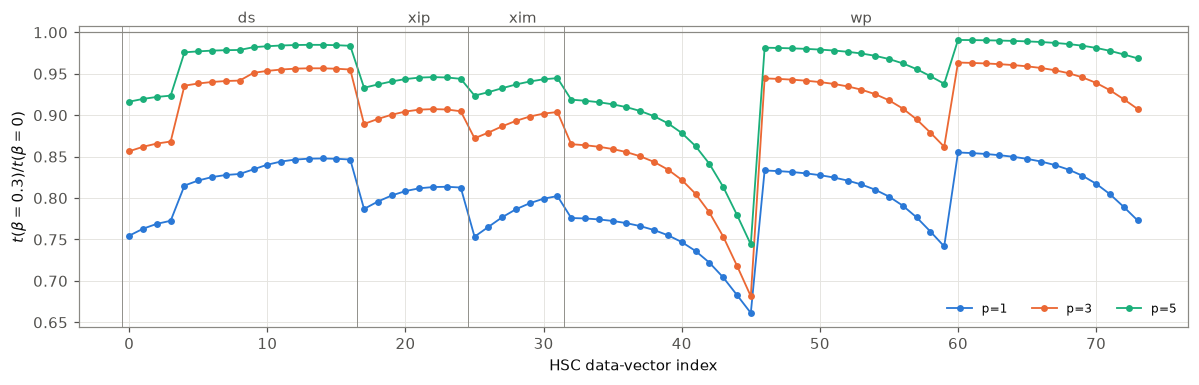

'\nx 軸：HSC data vector 的 index（ΔΣ 17、ξ+ 8、ξ- 7、wp 42）。\ny 軸：β = BETA_TEST 與 β = 0 的 theory 比值（其他參數相同，fiducial 宇宙學、文獻 MAP nuisance）。\n怎麼讀：每個 block 都應偏離 1；ΔΣ、wp 主要看 lens 紅移的 α(z_l)（加上 Kaiser），ξ± 看 source kernel 範圍的 α(z)。\n'

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(VEC0[P_LIST[0]]))
for k, p in enumerate(P_LIST):
    ax.plot(x, VECB[p]/VEC0[p], "o-", ms=3.5, lw=1.2, color=COLORS[k], label=f"p={p}")
for (name, lo, hi) in BLOCKS:
    ax.axvline(lo - 0.5, color="#8a8984", lw=0.6)
    ax.text((lo + hi)/2, 1.0, name, ha="center", va="bottom", color="#52514e", transform=ax.get_xaxis_transform())
ax.axhline(1, color="#8a8984", lw=0.8)
ax.set(xlabel="HSC data-vector index", ylabel=rf"$t(\beta={BETA_TEST})/t(\beta=0)$")
ax.legend(fontsize=8, ncol=len(P_LIST)); fig.tight_layout(); plt.show()

"""
x 軸：HSC data vector 的 index（ΔΣ 17、ξ+ 8、ξ- 7、wp 42）。
y 軸：β = BETA_TEST 與 β = 0 的 theory 比值（其他參數相同，fiducial 宇宙學、文獻 MAP nuisance）。
怎麼讀：每個 block 都應偏離 1；ΔΣ、wp 主要看 lens 紅移的 α(z_l)（加上 Kaiser），ξ± 看 source kernel 範圍的 α(z)。
"""

### A3. Kaiser 成長率 $f$ 是否也被 DETG 修改

$w_p$ 的 Kaiser 修正用 $\beta_K=f/b$。DETG 下 $P_L^{\rm DETG}=\alpha(a)\,P_L^{\Lambda\rm CDM}$ 且 $\alpha$ 與 $k$ 無關，所以 $D^{\rm DETG}=\sqrt{\alpha}\,D^{\Lambda\rm CDM}$，

$$f^{\rm DETG}(a)=f^{\Lambda\rm CDM}(a)+\frac12\frac{d\ln\alpha}{d\ln a},\qquad
\frac{\beta_K(\beta)}{\beta_K(0)}=1+\frac{d\ln\alpha/d\ln a}{2f^{\Lambda\rm CDM}}\quad(\text{同一組 } b).$$

`hsc_lens.py` 在 `z_l_eff[i]` 用 `gr.f(zl, f_lcdm)`（解析式 $f_{\Lambda\rm CDM}-1.5\beta p\,\Omega_m(a)x^p/\alpha$）。這裡用**數值微分** $d\ln\alpha/d\ln a$ 與 CCL 的 $f_{\Lambda\rm CDM}$ 獨立計算期望比值，與 hook 記錄到的 $\beta_K$ 比值比較（要求相對差 $<10^{-5}$）。若比值恰好等於 1，表示 Kaiser 用的是 ΛCDM 的 $f$；此時下一個 cell 會估計這個遺漏的影響。

> `_kaiser_ratio` 在每次 `theory_vector` 中依 lens bin 順序各呼叫一次（`for i in range(3)`），呼叫次數會印出來確認。

In [11]:
def dlnalpha_dlna(gr, a, eps=1e-4):
    return (np.log(gr.alpha(a*np.exp(eps))) - np.log(gr.alpha(a*np.exp(-eps))))/(2*eps)

def f_ratio_expected(parts, z):
    a = 1/(1 + np.atleast_1d(z))
    f_lcdm = ccl.growth_rate(parts["base"], a)
    return 1 + 0.5*dlnalpha_dlna(parts["gr"], a)/f_lcdm

_, _, _ = evaluate(MJ, dict(THETA0, beta_detg=0.0));       KLOG0 = list(KAISER_LOG)
_, capsK, _ = evaluate(MJ, dict(THETA0, beta_detg=BETA_TEST)); KLOGB = list(KAISER_LOG)
nb = len(NZL_RAW)

rowsA3, KAISER_MISSING = [], {}
for p in P_LIST:
    name = f"hsc_p{p}"
    k0 = [kb for (n, i, kb) in KLOG0 if n == name]
    kB = [kb for (n, i, kb) in KLOGB if n == name]
    if len(k0) == 0:
        rowsA3.append(dict(p=p, call=None, note="HSC 沒有呼叫 _kaiser_ratio（Kaiser 關閉？）", ok=False)); continue
    zeff = list(MJ.likelihood[name].z_l_eff)
    for i, (x0, xB) in enumerate(zip(k0, kB)):
        ib_ = i % nb
        z_i = float(zeff[ib_])
        ex = float(f_ratio_expected(PARTS_B[p], z_i)[0])
        ratio = xB/x0
        missing = abs(ratio - 1) < 1e-10
        ok = abs(ratio/ex - 1) < 1e-5
        if missing:
            KAISER_MISSING[(name, i)] = ex
        rowsA3.append(dict(p=p, call=i, lens_bin=ib_, z_l_eff=z_i, z_in_bin_range=LENS_ZRANGE[ib_][0] <= z_i <= LENS_ZRANGE[ib_][1],
                           betaK_0=x0, betaK_beta=xB, ratio_recorded=ratio, ratio_expected=ex,
                           note="HSC Kaiser 使用 ΛCDM f（DETG 未修改 f）" if missing else "", ok=bool(ok)))
dfA3 = pd.DataFrame(rowsA3)
print("每個 HSC instance 的 _kaiser_ratio 呼叫次數：", {p: capsK[f"hsc_p{p}"]["n_kaiser"] for p in P_LIST})
A3_ok = bool(dfA3.ok.all())
print("A3 全部通過：", A3_ok)
dfA3.round(5)

每個 HSC instance 的 _kaiser_ratio 呼叫次數： {1: 3, 3: 3, 5: 3}
A3 全部通過： True


,p,call,lens_bin,z_l_eff,z_in_bin_range,betaK_0,betaK_beta,ratio_recorded,ratio_expected,note,ok
0,1,0,0,0.2607,True,0.30535,0.20812,0.68159,0.68159,,True
1,1,1,1,0.5106,True,0.28715,0.21668,0.75460,0.75460,,True
2,1,2,2,0.6264,True,0.28576,0.22433,0.78503,0.78503,,True
3,3,0,0,0.2607,True,0.30535,0.15570,0.50991,0.50991,,True
4,3,1,1,0.5106,True,0.28715,0.22799,0.79398,0.79398,,True
5,3,2,2,0.6264,True,0.28576,0.24664,0.86308,0.86308,,True
6,5,0,0,0.2607,True,0.30535,0.17008,0.55699,0.55699,,True
7,5,1,1,0.5106,True,0.28715,0.25690,0.89465,0.89465,,True
8,5,2,2,0.6264,True,0.28576,0.27053,0.94669,0.94669,,True


In [12]:
# 若 Kaiser 的 f 沒有被修改：估計遺漏的影響（beta = BETA_TEST，其他參數 fiducial）
dfA3b = None
if KAISER_MISSING:
    try:
        KAISER_FSCALE.update(KAISER_MISSING)
        _, capsF, _ = evaluate(MJ, dict(THETA0, beta_detg=BETA_TEST))
    finally:
        KAISER_FSCALE.clear()
    rows = []
    for p in P_LIST:
        h = MJ.likelihood[f"hsc_p{p}"]
        d = capsF[f"hsc_p{p}"]["vec"] - VECB[p]
        lo, hi = edges[3], edges[4]
        rows.append(dict(p=p, dchi2_total=float(d @ h.inv_cov @ d),
                         max_rel_wp=float(np.max(np.abs(d[lo:hi]/VECB[p][lo:hi])))))
    dfA3b = pd.DataFrame(rows)
    print(f"Kaiser f 改成 DETG 值後，HSC theory 的變化（beta={BETA_TEST}）：")
    print("dchi2 << 1 → 對這個初步判斷可忽略；但正式 MCMC 前應在 hsc_lens.py 裡改用 DETG 的 f。")
    display(dfA3b.round(4))
else:
    print("Kaiser 的 f 已隨 DETG 修改（或 Kaiser 未啟用，見上表），不需要影響評估。")

Kaiser 的 f 已隨 DETG 修改（或 Kaiser 未啟用，見上表），不需要影響評估。


### A3b. IA（NLA）的成長正規化：目前**未隨 DETG 修改**（影響評估，資訊項）

`theory_vector` 的 cosmic shear 用 `ccl.WeakLensingTracer(base, ..., ia_bias=(z, A_IA))`。CCL 的 NLA kernel 為 $-A_{\rm IA}C_1\rho_{\rm cr}\Omega_m/D(z)$，其中 $D$ 取自傳入的 cosmology，也就是 **ΛCDM 的 `base`**；而 $C_\ell$ 用的是修改後的 `pk_nl`。

NLA 的 intrinsic shear 正比於形成時的 tidal field（$\propto\delta(z)/D(z)$），所以 DETG 下 $P_{\rm II}\propto P_\delta^{\rm DETG}/D_{\rm DETG}^2=P_\delta^{\Lambda\rm CDM}/D_{\Lambda\rm CDM}^2$，應與 ΛCDM 相同；目前的寫法則是 $\alpha\,P_\delta^{\Lambda\rm CDM}/D_{\Lambda\rm CDM}^2$，IA 項多了一個 $\sqrt{\alpha}$（GI）或 $\alpha$（II）。對應的修正是 $A_{\rm IA}\to A_{\rm IA}/\sqrt{\alpha(z)}$。

這個 cell 先用與 `hsc_lens.py` 完全相同的步驟重建 $\xi_\pm$（必須與攔截到的向量 bitwise 一致，確認重建正確），再算修正後的 $\xi_\pm$，列出 $\Delta\chi^2$。在 $A_{\rm IA}$ 自由的情況下，這個差異會被 $A_{\rm IA}$ 部分吸收；但它會讓 $A_{\rm IA}$ 與 $\beta$ 產生**人為**的相關。是否採用這個修正屬於模型選擇（請對照 Terasawa et al. 2025 的作法），所以這裡只評估影響，不列入 pass/fail。

In [13]:
def xi_pm_rebuild(h, parts, ia_detg_fix=False):
    """與 HSC_Lens.theory_vector 的 cosmic-shear 部分逐行相同；ia_detg_fix=True 時 A_IA → A_IA/√α(z)"""
    base, cosmo, gr, pv = parts["base"], parts["cosmo"], parts["gr"], parts["pv"]
    nz_true = np.interp(h.z_s + pv["dpz_0"], h.z_s, h.nz_s, left=0.0, right=0.0)
    A = np.full_like(h.z_s, float(pv["AIA"]), dtype=float)
    if ia_detg_fix:
        A = A/np.sqrt(gr.alpha(1.0/(1.0 + h.z_s)))
    tr = ccl.WeakLensingTracer(base, dndz=(h.z_s, nz_true), ia_bias=(h.z_s, A))
    ell = np.geomspace(0.1, 1e5, 1024)
    cl = ccl.angular_cl(base, tr, tr, ell=ell, p_of_k_a=cosmo.get_nonlin_power())
    fac_m = (1.0 + pv["dm_0"])**2
    a_psf, b_psf = pv["alphapsf"], pv["betapsf"]
    out = []
    for which, table, cut, cols in (("GG+", h.xip_t, h.xip_cut, (0, 2, 4)), ("GG-", h.xim_t, h.xim_cut, (1, 3, 5))):
        th = table["ANG"][cut]/60.0
        val = fac_m*ccl.correlation(base, ell=ell, C_ell=cl, theta=th, type=which, method="FFTLog")
        pp, pq, qq = (h.psf[cut, c] for c in cols)
        out.append(val + a_psf**2*pp + 2*a_psf*b_psf*pq + b_psf**2*qq)
    return np.concatenate(out)

lo_xi, hi_xi = edges[1], edges[3]          # xi+ 與 xi- 在 data vector 中的範圍
rowsIA = []
for p in P_LIST:
    h = MJ.likelihood[f"hsc_p{p}"]
    xi_cur = xi_pm_rebuild(h, PARTS_B[p])
    rebuild_rel = float(np.max(np.abs(xi_cur/VECB[p][lo_xi:hi_xi] - 1)))
    xi_fix = xi_pm_rebuild(h, PARTS_B[p], ia_detg_fix=True)
    d = np.zeros_like(VECB[p]); d[lo_xi:hi_xi] = xi_fix - xi_cur
    rowsIA.append(dict(p=p, beta=BETA_TEST, AIA=PARTS_B[p]["pv"]["AIA"], rebuild_max_rel=rebuild_rel,
                       rebuild_ok=rebuild_rel < 1e-10, max_rel_xi_change=float(np.max(np.abs((xi_fix - xi_cur)/xi_cur))),
                       dchi2_HSC=float(d @ h.inv_cov @ d)))
dfIA = pd.DataFrame(rowsIA)
print("IA 成長正規化修正（A_IA → A_IA/√α）在 beta = BETA_TEST 的影響；dchi2 << 1 → 對初步判斷可忽略")
dfIA

IA 成長正規化修正（A_IA → A_IA/√α）在 beta = BETA_TEST 的影響；dchi2 << 1 → 對初步判斷可忽略


,p,beta,AIA,rebuild_max_rel,rebuild_ok,max_rel_xi_change,dchi2_HSC
0,1,0.3,3.172051,0.0,True,0.001624,6.549873e-04
1,3,0.3,3.172051,0.0,True,0.000324,3.788136e-05
2,5,0.3,3.172051,0.0,True,0.000031,3.470735e-07


### A4. 非物理參數與邊界（joint）

$\beta\ge1$：$\alpha(z=0)\le0$。ACT 的 `build_ccl` 會捕捉 `GrowthModel` 的 `ValueError` 並回傳 $-\infty$；但 `HSC_Lens._build_cosmology` **沒有**捕捉，`GrowthModel("detg", ...)` 會直接丟出例外（`stop_at_error=True` 時整個 run 停掉）。

- 若 $\beta$ 的 flat prior 上限 $\le1$（`BETA_PRIOR`），sampler 不會提出 $\beta\ge1$ 的點（prior 先擋掉），這個例外不影響 MCMC → 記為通過（附註）。
- 若 prior 上限 $>1$（例如 ACT notebook 的 `base_params` 用了 1.5），必須先在 `hsc_lens.py` 加上與 ACT 相同的 `try/except ValueError → return -np.inf`。

$\beta<1$ 時所有 likelihood 都應有限。

In [14]:
rowsA4 = []
for b in [-0.9, -0.3, 0.95, 0.99, 1.0, 1.2]:
    expect_finite = b < 1
    try:
        ll, _, _ = evaluate(MJ, dict(THETA0, beta_detg=b))
        tot = float(sum(ll.values()))
        hsc_fin = all(np.isfinite(ll[f"hsc_p{p}"]) for p in P_LIST if f"hsc_p{p}" in ll)
        ok = (np.isfinite(tot) == expect_finite) and (hsc_fin if expect_finite else True)
        note = ""
    except Exception as e:
        tot = np.nan
        ok = (not expect_finite) and BETA_PRIOR[1] <= 1.0
        note = (f"exception: {e!r}"[:100]
                + ("（prior 上限 ≤ 1，sampler 不會到達此點）" if ok else "（需在 hsc_lens.py 捕捉 ValueError）"))
    rowsA4.append(dict(beta=b, lnL_joint_total=tot, expected_finite=expect_finite, ok=bool(ok), note=note))
dfA4 = pd.DataFrame(rowsA4)
print("A4 全部通過：", dfA4.ok.all())
dfA4

A4 全部通過： True


,beta,lnL_joint_total,expected_finite,ok,note
0,-0.90,-1780.041647,True,True,
1,-0.30,-658.309440,True,True,
2,0.95,-540.224298,True,True,
3,0.99,-584.615957,True,True,
4,1.00,-inf,False,True,
5,1.20,-inf,False,True,


### A5. ACT 在 joint model 中 = ACT 單獨（ACT notebook 的設定）

同一組參數點，把 joint model 中的 ACT $\ln\mathcal{L}$ 與「只放 ACT」的 model（ACT notebook 的 CAMB 設定 `CAMB_EXTRA`、同樣的 $\tau$、$m_\nu$）比較。若不同，通常是 HSC yaml 的 CAMB `extra_args`（例如 halofit 版本、中微子設定）改變了 ACT 的 $C_L^{\kappa\kappa}$——正式 MCMC 必須決定用哪一組設定。

In [15]:
def make_act_only_model(p_list):
    params = {"ombh2": {"prior": {"min": 0.005, "max": 0.1}}, "omch2": {"prior": {"min": 0.005, "max": 0.99}},
              "H0": {"prior": {"min": 40, "max": 100}}, "ns": {"prior": {"min": 0.8, "max": 1.2}},
              "logA": {"prior": {"min": 1.6, "max": 4.0}, "drop": True},
              "As": {"value": "lambda logA: 1e-10*np.exp(logA)"}, "tau": TAU_FIX, "mnu": MNU_FIX,
              "beta_detg": {"prior": {"min": BETA_PRIOR[0], "max": BETA_PRIOR[1]}}}
    info = {"likelihood": {f"act_p{p}": act_opts(p) for p in p_list},
            "theory": {"camb": {"extra_args": dict(CAMB_EXTRA), "stop_at_error": True}},
            "params": params, "packages_path": PKG, "debug": False}
    m = get_model(info)
    for n, lik in m.likelihood.items():
        _DATA2NAME[id(lik.data)] = n
    return m

M_ACT = make_act_only_model(P_LIST)
pts = [dict(THETA0)]
for _ in range(2):
    pts.append(dict(THETA0, ombh2=RNG.normal(0.0223, 0.0004), omch2=RNG.uniform(0.10, 0.14), H0=RNG.uniform(60, 76),
                    ns=RNG.uniform(0.94, 0.99), logA=RNG.uniform(2.9, 3.2), beta_detg=RNG.uniform(-0.4, 0.4)))
rowsA5 = []
for ip, pt in enumerate(pts):
    llj, cj, _ = evaluate(MJ, pt)
    lla, ca, _ = evaluate(M_ACT, {k: pt[k] for k in M_ACT.parameterization.sampled_params()})
    for p in P_LIST:
        n = f"act_p{p}"
        rb = float(np.max(np.abs(cj[n]["binned"]/ca[n]["binned"] - 1)))
        dl = llj[n] - lla[n]
        rowsA5.append(dict(point=ip, p=p, lnL_joint=llj[n], lnL_ACTonly=lla[n], dlnL=dl, max_rel_binned=rb,
                           ok=bool(abs(dl) < 1e-3 and rb < 1e-5)))
dfA5 = pd.DataFrame(rowsA5)
print("joint 的 CAMB extra_args：", JOINT_THEORY["camb"]["extra_args"])
print("ACT-only 的 CAMB extra_args：", CAMB_EXTRA)
print("A5 全部通過：", dfA5.ok.all())
dfA5.round(6)

INFO:camb:`camb` module loaded successfully from /home/andromeda/miniforge3/envs/cosmo/lib/python3.12/site-packages/camb


[camb] `camb` module loaded successfully from /home/andromeda/miniforge3/envs/cosmo/lib/python3.12/site-packages/camb


INFO:act_p1:ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


Loading ACT DR6 lensing likelihood v1.2...
[act_p1] ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


INFO:act_p3:ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


Loading ACT DR6 lensing likelihood v1.2...
[act_p3] ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


INFO:act_p5:ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON


Loading ACT DR6 lensing likelihood v1.2...
[act_p5] ACT DR6 lensing: variant=act_baseline lens_only=True like_corrections=False growth_ratio=ON
joint 的 CAMB extra_args： {'lens_potential_accuracy': 1}
ACT-only 的 CAMB extra_args： {'lens_potential_accuracy': 1}
A5 全部通過： True


,point,p,lnL_joint,lnL_ACTonly,dlnL,max_rel_binned,ok
0,0,1,-7.050589,-7.050589,0.0,0.0,True
1,0,3,-7.050589,-7.050589,0.0,0.0,True
2,0,5,-7.050589,-7.050589,0.0,0.0,True
3,1,1,-13.393529,-13.393529,0.0,0.0,True
4,1,3,-20.184243,-20.184243,0.0,0.0,True
5,1,5,-21.699006,-21.699006,0.0,0.0,True
6,2,1,-25.326931,-25.326931,0.0,0.0,True
7,2,3,-22.736245,-22.736245,0.0,0.0,True
8,2,5,-22.285142,-22.285142,0.0,0.0,True


### A6. Sampler 情境：cobaya cache 開著時，joint model 的所有 likelihood 是否正確

與 ACT notebook 的 A4 相同的想法：cobaya CAMB 在只改 $A_s$、$n_s$ 時重用 transfer function；只改 HSC nuisance 時完全不重算 CAMB。若 HSC 在 likelihood 內部另外跑 CAMB（例如 CCL `boltzmann_camb`），可能讓同一 run 的 ACT 算錯。序列包含：全部重算 → 只改 $A_s$ → 只改 $n_s$ → 只改 HSC nuisance → 改 $A_s$ 與 $\beta$。

In [16]:
nuis_move = NUIS[:2]
SEQ = [dict(THETA0),
       dict(THETA0, H0=THETA0["H0"] + 0.5)]
SEQ.append(dict(SEQ[-1], logA=THETA0["logA"] + 0.05))
SEQ.append(dict(SEQ[-1], ns=THETA0["ns"] + 0.01))
SEQ.append(dict(SEQ[-1], **{k: THETA0[k] + 0.5*PRI[k]["std"] for k in nuis_move}))
SEQ.append(dict(SEQ[-1], beta_detg=0.2, logA=THETA0["logA"] - 0.05))
SEQ_DESC = ["fiducial", "H0 (全部重算)", "只改 As", "只改 ns", f"只改 HSC nuisance {nuis_move}", "As + beta"]

rowsA6 = []
for i, pt in enumerate(SEQ):
    ll_c, _ = MJ.loglikes(pt, as_dict=True, cached=True)
    ll_u, _ = MJ.loglikes(pt, as_dict=True, cached=False)
    row = dict(step=i, change=SEQ_DESC[i])
    for n in MJ.likelihood:
        row[f"dlnL_{n}"] = ll_c[n] - ll_u[n]
    rowsA6.append(row)
dfA6 = pd.DataFrame(rowsA6)
A6_TOL = 1e-2
A6_ok = bool((dfA6[[c for c in dfA6 if c.startswith("dlnL_")]].abs() < A6_TOL).all().all())
print("A6（cache 開著，joint）一致：", A6_ok)
if not A6_ok:
    print("→ 有 likelihood 在 cache 情境下算錯。HSC_Lens._build_cosmology 用 ccl.Cosmology(transfer_function='boltzmann_camb')，"
          "\n  在同一個 process 裡另外跑 CAMB，與 ACT notebook A4 修正前的情況相同。"
          "\n  修法：HSC 的 get_requirements 加上與 ACTDR6LensDETG 相同的 Pk_interpolator 需求，"
          "\n  _build_cosmology 改用 act_lens.CCLState.build_ccl(pv, provider.get_Pk_interpolator(...), ...)（base 與 DETG 都用 CosmologyCalculator）。"
          "\n  B 節的 Fisher 一律用 cached=False，不受此問題影響；但 MCMC 前必須修正。")
dfA6.round(5)

A6（cache 開著，joint）一致： True


,step,change,dlnL_act_p1,dlnL_hsc_p1,dlnL_act_p3,dlnL_hsc_p3,dlnL_act_p5,dlnL_hsc_p5
0,0,fiducial,0.0,0.0,0.0,0.0,0.0,0.0
1,1,H0 (全部重算),0.0,0.0,0.0,0.0,0.0,0.0
2,2,只改 As,0.0,0.0,0.0,0.0,0.0,0.0
3,3,只改 ns,0.0,0.0,0.0,0.0,0.0,0.0
4,4,"只改 HSC nuisance ['b1', 'b2']",0.0,0.0,0.0,0.0,0.0,0.0
5,5,As + beta,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
# affects = "Fisher"：影響本 notebook 的 B/C 節；"MCMC"：只影響之後的 sampler run
summaryA = pd.DataFrame([
    dict(test="A0 DETG 選項 / p 一致 / beta 為輸入參數 / HSC 結構", affects="Fisher", passed=bool(dfA0.ok.all())),
    dict(test="A1 beta=0：HSC 重現 ΛCDM（chi2≈71.80）、cobaya=direct、detg(β=0)≈none、與 p 無關", affects="Fisher", passed=A1_ok),
    dict(test="A2 beta≠0：alpha、P_lin 比值、四個 block 都有反應", affects="Fisher", passed=A2_ok),
    dict(test="A3 Kaiser f 隨 DETG 修改", affects="Fisher", passed=A3_ok),
    dict(test="A5 joint 中的 ACT = ACT 單獨", affects="Fisher", passed=bool(dfA5.ok.all())),
    dict(test="A4 非物理 beta：-inf 或被 prior 擋掉", affects="MCMC", passed=bool(dfA4.ok.all())),
    dict(test="A6 sampler 情境（cache 開著）全部一致", affects="MCMC", passed=A6_ok),
])
A_FISHER_OK = bool(summaryA[summaryA.affects == "Fisher"].passed.all())
A_MCMC_OK = bool(summaryA[summaryA.affects == "MCMC"].passed.all())
print("資訊項 A3b（IA 成長正規化）在 beta=BETA_TEST 的 dchi2_HSC：",
      {int(r.p): round(r.dchi2_HSC, 4) for _, r in dfIA.iterrows()},
      "| 重建一致：", bool(dfIA.rebuild_ok.all()))
summaryA

資訊項 A3b（IA 成長正規化）在 beta=BETA_TEST 的 dchi2_HSC： {1: 0.0007, 3: 0.0, 5: 0.0} | 重建一致： True


,test,affects,passed
0,A0 DETG 選項 / p 一致 / beta 為輸入參數 / HSC 結構,Fisher,True
1,A1 beta=0：HSC 重現 ΛCDM（chi2≈71.80）、cobaya=direc...,Fisher,True
2,A2 beta≠0：alpha、P_lin 比值、四個 block 都有反應,Fisher,True
3,A3 Kaiser f 隨 DETG 修改,Fisher,True
4,A5 joint 中的 ACT = ACT 單獨,Fisher,True
5,A4 非物理 beta：-inf 或被 prior 擋掉,MCMC,True
6,A6 sampler 情境（cache 開著）全部一致,MCMC,True


#### `hsc_lens.py` 中各項 DETG 修改效應的對照（依程式碼逐項確認）

DETG：$P_L\to\alpha(a)P_L$、$D\to\sqrt{\alpha}\,D$、$f\to f+\tfrac12 d\ln\alpha/d\ln a$；背景（距離、$\rho_m$、$\Sigma_{\rm cr}$）維持 ΛCDM。

| 項目 | `hsc_lens.py` 的作法 | 狀態 | 測試 |
|---|---|---|---|
| 線性 $P$ | `pk *= gr.alpha(a)` 後建 `CosmologyCalculator` | ✓ | A2 |
| 非線性 $P$ | halofit 作用在修改後的線性 $P$（不是 $\alpha\times P_{\rm NL}$） | ✓ | A2（`Pnl_ratio_k1` ≠ α） |
| $\Delta\Sigma$、$w_p$（real space） | `correlation_3d(base, p_of_k_a=pk_nl)`，`pk_nl` 來自修改後的 cosmology | ✓ | A2 |
| Kaiser $\beta_K=f/b$ | `gr.f(zl, f_lcdm)` 在 `z_l_eff` | ✓ | A3 |
| Kaiser 的線性 $\xi$ | `pk_lin` 來自修改後的 cosmology | ✓ | A2（$w_p$ 有反應） |
| Magnification | `angular_cl(..., p_of_k_a=pk_nl)` | ✓ | A2 |
| $\xi_\pm$ | `angular_cl(..., p_of_k_a=pk_nl)` | ✓ | A2 |
| **IA（NLA）** | tracer 建在 `base` 上 → kernel 用 **ΛCDM 的 $D(z)$** | ✗ 未修改 | A3b（影響評估） |
| $\sigma_8$、$S_8$ derived | `sigma8(base) × gr.ratio(0)` $=\sigma_8\sqrt{1-\beta}$ | ✓ | B 節沿用同一定義 |
| $\beta\ge1$ | `GrowthModel` 丟 `ValueError`，HSC 未捕捉 | △ | A4 |
| 線性 $P$ 來源 | `boltzmann_camb`（likelihood 內另跑 CAMB） | △ MCMC 前需修 | A6 |
| 中微子 | HSC 固定 `MNU_FID=0.06`、CCL 預設 `mass_split="normal"`，不讀 cobaya 的 `mnu`；ACT 用 cobaya CAMB（1 顆有質量）+ `mass_split="single"` | △ 兩邊背景有 $\mathcal{O}(10^{-4})$ 差異 | — |
| PSF、$\Sigma_{\rm cr}^{-1}$、photo-z/shear nuisance | 與成長無關 | ✓ | — |

## B. 聯合 Fisher：ACT、HSC、ACT+HSC

### B1. Theory vector 的導數

$$F^{X}_{ij}=\frac{\partial\mathbf{t}_X}{\partial\theta_i}^{\!T}\mathbf{C}_X^{-1}\frac{\partial\mathbf{t}_X}{\partial\theta_j},\qquad
F^{\rm ACT+HSC}=F^{\rm ACT}+F^{\rm HSC}+F^{\rm prior}$$

- 參數：joint model 的全部 sampled params（宇宙學 5 個、$\beta$、HSC nuisance）。ACT 對 HSC nuisance 的導數為 0。
- ACT 與 HSC 之間沒有 cross-covariance（不同天區/資料，與正式 MCMC 的假設相同）。
- 兩種步長（`DERIV_SCALES`）檢查導數穩定性（只對宇宙學、$\beta$、`dpz_0`；其餘 nuisance 在 theory 中是多項式，中央差分已精確）；若存在 `ACT_FISHER_FILE`，ACT 的 Jacobian 與 ACT notebook 的結果交叉比對。
- Derived（與 `HSC_Lens.logp` 相同定義，從攔截到的 HSC `base` 計算）：$\sigma_8^{\rm DETG}=\sigma_8^{\Lambda\rm CDM}\sqrt{1-\beta}$、$S_8=\sigma_8^{\rm DETG}(\Omega_m/0.3)^{0.5}$、$S_8^{\rm CMBL}=\sigma_8^{\rm DETG}(\Omega_m/0.3)^{0.25}$。
- HSC 每次求值都在 likelihood 內跑一次 `boltzmann_camb`（每個 $p$ 一次），所以一次求值比 ACT notebook 慢很多；下一個 cell 會印出預估時間。

In [18]:
CINV_A = MJ.likelihood[f"act_p{P_LIST[0]}"].data["cinv"]
CINV_H = MJ.likelihood[f"hsc_p{P_LIST[0]}"].inv_cov

DERIVED = ["sigma8_DETG", "S8_DETG", "S8CMBL_DETG"]
def derived_from_caps(caps):
    """與 HSC_Lens.logp 的 derived 定義相同：σ8^DETG = σ8^ΛCDM(base) × gr.ratio(0) = σ8 √(1-β)"""
    P_ = hsc_parts(caps[f"hsc_p{P_LIST[0]}"])
    s8 = float(ccl.sigma8(P_["base"]))*float(P_["gr"].ratio(0.0))
    om = float(P_["om"])
    return np.array([s8, s8*(om/0.3)**0.5, s8*(om/0.3)**0.25])

def theory_all(point):
    ll, caps, _ = evaluate(MJ, point)
    TA = {p: caps[f"act_p{p}"]["binned"] for p in P_LIST}
    TH = {p: caps[f"hsc_p{p}"]["vec"] for p in P_LIST}
    return TA, TH, derived_from_caps(caps), ll

# 第二種步長只用來檢查「非多項式」參數的穩定性：b_i（wp ∝ b²、ΔΣ ∝ b）、A_IA、dm_0、PSF（二次）、alphamag（線性）
# 在 theory 中是多項式，中央差分已是精確的；dpz_0 經過 n(z) 內插，需要檢查。
STAB_PARS = COSMO + ["beta_detg"] + [k for k in ("dpz_0",) if k in PARS]

t0 = time.time(); T0A, T0H, D0, _ = theory_all(THETA0); t_eval = time.time() - t0
n_eval = 2*len(PARS) + 2*len(STAB_PARS)*(len(DERIV_SCALES) - 1)
print(f"一次求值 {t_eval:.1f}s；導數需要 {n_eval} 次，約 {n_eval*t_eval/60:.1f} 分鐘")
print("Asimov S/N：ACT =", round(float(np.sqrt(T0A[P_LIST[0]] @ CINV_A @ T0A[P_LIST[0]])), 1),
      "| HSC =", round(float(np.sqrt(T0H[P_LIST[0]] @ CINV_H @ T0H[P_LIST[0]])), 1))

一次求值 8.6s；導數需要 48 次，約 6.8 分鐘
Asimov S/N：ACT = 38.9 | HSC = 61.0


In [19]:
def derivatives(scale, pars=None):
    """pars=None：所有參數；否則只算列出的欄（其他欄為 NaN）"""
    JA = {p: np.full((T0A[p].size, len(PARS)), np.nan) for p in P_LIST}
    JH = {p: np.full((T0H[p].size, len(PARS)), np.nan) for p in P_LIST}
    G = np.full((len(DERIVED), len(PARS)), np.nan)
    for j, par in enumerate(PARS):
        if pars is not None and par not in pars:
            continue
        h = STEPS[par]*scale
        up, dn = dict(THETA0), dict(THETA0)
        up[par] += h; dn[par] -= h
        TAu, THu, Du, _ = theory_all(up); TAd, THd, Dd, _ = theory_all(dn)
        for p in P_LIST:
            JA[p][:, j] = (TAu[p] - TAd[p])/(2*h)
            JH[p][:, j] = (THu[p] - THd[p])/(2*h)
        G[:, j] = (Du - Dd)/(2*h)
    return JA, JH, G

t0 = time.time()
JACS = {s: derivatives(s, pars=None if s == DERIV_SCALES[-1] else STAB_PARS) for s in DERIV_SCALES}
JA, JH, GD = JACS[DERIV_SCALES[-1]]
assert all(np.isfinite(JA[p]).all() and np.isfinite(JH[p]).all() for p in P_LIST) and np.isfinite(GD).all()
print(f"derivatives done ({(time.time()-t0)/60:.1f} min)")

def stab(Jbig, Jsmall):
    out = []
    for j in range(len(PARS)):
        m = np.max(np.abs(Jsmall[:, j]))
        if m == 0 or not np.isfinite(Jbig[:, j]).all():
            out.append(np.nan); continue
        out.append(float(np.max(np.abs(Jbig[:, j] - Jsmall[:, j]))/m))
    return out

if len(DERIV_SCALES) > 1:
    s1, s2 = DERIV_SCALES[0], DERIV_SCALES[-1]
    rows = []
    for p in P_LIST:
        rows.append(pd.Series(stab(JACS[s1][0][p], JACS[s2][0][p]), index=PARS, name=f"ACT p={p}"))
        rows.append(pd.Series(stab(JACS[s1][1][p], JACS[s2][1][p]), index=PARS, name=f"HSC p={p}"))
    dfStab = pd.DataFrame(rows)
    print("導數穩定性 max|dT(h)-dT(h/2)|/max|dT(h/2)|（< 1e-2 為佳；NaN = 該資料對此參數無反應）")
    display(dfStab.style.format("{:.1e}"))

derivatives done (6.8 min)
導數穩定性 max|dT(h)-dT(h/2)|/max|dT(h/2)|（< 1e-2 為佳；NaN = 該資料對此參數無反應）


,ombh2,omch2,H0,ns,logA,b1,b2,b3,AIA,dm_0,dpz_0,alphapsf,betapsf,alphamag_1,alphamag_2,alphamag_3,beta_detg
ACT p=1,9.6e-03,1.4e-03,9.0e-05,4.3e-05,4.4e-05,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.4e-05
HSC p=1,5.0e-05,1.1e-04,3.8e-03,1.1e-04,5.2e-05,nan,nan,nan,nan,nan,1.4e-05,nan,nan,nan,nan,nan,9.5e-06
ACT p=3,9.6e-03,1.4e-03,9.0e-05,4.3e-05,4.4e-05,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.9e-06
HSC p=3,5.0e-05,1.1e-04,3.8e-03,1.1e-04,5.2e-05,nan,nan,nan,nan,nan,1.4e-05,nan,nan,nan,nan,nan,3.6e-06
ACT p=5,9.6e-03,1.4e-03,9.0e-05,4.3e-05,4.4e-05,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,2.0e-04
HSC p=5,5.0e-05,1.1e-04,3.8e-03,1.1e-04,5.2e-05,nan,nan,nan,nan,nan,1.4e-05,nan,nan,nan,nan,nan,1.4e-04


In [20]:
# 與 ACT notebook 的 Jacobian 交叉比對（相同 fiducial、相同步長時應幾乎相同）
if ACT_FISHER_FILE and os.path.exists(ACT_FISHER_FILE):
    z_ = np.load(ACT_FISHER_FILE, allow_pickle=True)
    prs = [str(x) for x in z_["params"]]
    th_old = dict(zip(prs, z_["theta0"]))
    same_fid = all(abs(th_old[k] - THETA0[k]) < 1e-12 for k in prs)
    print("ACT notebook fiducial 相同：", same_fid)
    cols = [PARS.index(k) for k in prs]
    for p in P_LIST:
        if f"J_p{p}" not in z_: continue
        Jold = z_[f"J_p{p}"]
        rel = np.max(np.abs(JA[p][:, cols] - Jold), axis=0)/np.max(np.abs(Jold), axis=0)
        print(f"p={p}: max rel diff per param", dict(zip(prs, np.round(rel, 5))))
else:
    print("沒有 ACT_FISHER_FILE，略過交叉比對。")

沒有 ACT_FISHER_FILE，略過交叉比對。


### B2. 三種組合的 $\beta$ 約束

- $\sigma_{\rm marg}$：其他參數 marginalize 後的 $1\sigma$；$\sigma_{\rm cond}=1/\sqrt{F_{\beta\beta}}$；簡併倍率 $=\sigma_{\rm marg}/\sigma_{\rm cond}$。
- **gain** $=\sigma_\beta^{\rm ACT}/\sigma_\beta^{\rm ACT+HSC}$：加入 HSC 後 $\beta$ 誤差縮小幾倍。
- **synergy** $=\sigma_\beta^{\rm naive}/\sigma_\beta^{\rm ACT+HSC}$，其中 naive 是把兩者的 1D 邊際資訊直接相加（$1/\sigma_{\rm naive}^2=I_A+I_H+1/\sigma_{\rm prior}^2$，$I_X=1/\sigma_X^2-1/\sigma_{\rm prior}^2$）。**synergy 明顯 > 1 才代表兩組資料的簡併方向不同、聯合分析真正「打破」簡併**；synergy ≈ 1 只是資訊相加。
- 矩陣先以對角縮放再求逆（參數尺度差很多，例如 $H_0$ 與 $\omega_b$）。

In [21]:
SIG_P = np.array([PRI[k]["std"] for k in PARS])
FP = np.diag(1/SIG_P**2)
SIG_PRIOR_BETA = SIG_P[IB]

def inv_scaled(F):
    d = 1/np.sqrt(np.diag(F))
    return d[:, None]*np.linalg.inv(d[:, None]*F*d[None, :])*d[None, :]

FA = {p: JA[p].T @ CINV_A @ JA[p] for p in P_LIST}
FH = {p: JH[p].T @ CINV_H @ JH[p] for p in P_LIST}
FISH = {"ACT": {p: FA[p] + FP for p in P_LIST},
        "HSC": {p: FH[p] + FP for p in P_LIST},
        "ACT+HSC": {p: FA[p] + FH[p] + FP for p in P_LIST}}
COV = {c: {p: inv_scaled(F) for p, F in d.items()} for c, d in FISH.items()}
COMBOS = list(FISH)

def rho(C, a, b):
    i, j = PARS.index(a), PARS.index(b)
    return float(C[i, j]/np.sqrt(C[i, i]*C[j, j]))

rows = []
for p in P_LIST:
    for c in COMBOS:
        F, Cm = FISH[c][p], COV[c][p]
        sb = float(np.sqrt(Cm[IB, IB])); sc = float(1/np.sqrt(F[IB, IB]))
        idx_l = [i for i in range(len(PARS)) if i != IB]
        C_l = inv_scaled(F[np.ix_(idx_l, idx_l)])
        row = dict(p=p, data=c, sigma_beta=sb, sigma_beta_over_prior=sb/SIG_PRIOR_BETA, sigma_cond=sc,
                   degeneracy=sb/sc, rho_beta_logA=rho(Cm, "beta_detg", "logA"),
                   rho_beta_omch2=rho(Cm, "beta_detg", "omch2"), rho_beta_H0=rho(Cm, "beta_detg", "H0"))
        for d, dn in enumerate(DERIVED):
            g = GD[d]
            row[f"sig_{dn}"] = float(np.sqrt(g @ Cm @ g))
            row[f"sig_{dn}_betafixed"] = float(np.sqrt(g[idx_l] @ C_l @ g[idx_l]))
        rows.append(row)
dfF = pd.DataFrame(rows)

rowsBr = []
for p in P_LIST:
    s = {c: float(np.sqrt(COV[c][p][IB, IB])) for c in COMBOS}
    I_A = max(1/s["ACT"]**2 - 1/SIG_PRIOR_BETA**2, 0.0); I_H = max(1/s["HSC"]**2 - 1/SIG_PRIOR_BETA**2, 0.0)
    s_naive = 1/np.sqrt(I_A + I_H + 1/SIG_PRIOR_BETA**2)
    rowsBr.append(dict(p=p, sigma_ACT=s["ACT"], sigma_HSC=s["HSC"], sigma_naive=s_naive, sigma_joint=s["ACT+HSC"],
                       gain_vs_ACT=s["ACT"]/s["ACT+HSC"], gain_vs_HSC=s["HSC"]/s["ACT+HSC"],
                       synergy=s_naive/s["ACT+HSC"]))
dfBreak = pd.DataFrame(rowsBr)
display(dfBreak.round(4))
dfF.round(4)

,p,sigma_ACT,sigma_HSC,sigma_naive,sigma_joint,gain_vs_ACT,gain_vs_HSC,synergy
0,1,0.5261,0.3811,0.3652,0.1788,2.9418,2.1311,2.0421
1,3,0.5683,0.3374,0.3355,0.2288,2.4835,1.4743,1.4663
2,5,0.5750,0.3610,0.3604,0.2964,1.9401,1.2178,1.2159


,p,data,sigma_beta,sigma_beta_over_prior,sigma_cond,degeneracy,rho_beta_logA,rho_beta_omch2,rho_beta_H0,sig_sigma8_DETG,sig_sigma8_DETG_betafixed,sig_S8_DETG,sig_S8_DETG_betafixed,sig_S8CMBL_DETG,sig_S8CMBL_DETG_betafixed
0,1,ACT,0.5261,0.9112,0.1278,4.1156,0.8189,-0.4617,-0.0081,0.1788,0.0361,0.1995,0.0452,0.1857,0.0199
1,1,HSC,0.3811,0.6601,0.0265,14.3763,0.9286,-0.3167,-0.0742,0.0757,0.0568,0.0677,0.0404,0.0681,0.0437
2,1,ACT+HSC,0.1788,0.3097,0.0260,6.8824,0.6552,-0.2917,-0.2733,0.0712,0.0305,0.0597,0.0202,0.0621,0.0149
3,3,ACT,0.5683,0.9844,0.3907,1.4546,0.3784,-0.1712,-0.0033,0.2236,0.0361,0.2354,0.0452,0.2267,0.0199
4,3,HSC,0.3374,0.5843,0.0554,6.0923,0.7915,-0.3158,-0.0677,0.1053,0.0568,0.1026,0.0404,0.1013,0.0437
5,3,ACT+HSC,0.2288,0.3964,0.0551,4.1549,0.4399,-0.2777,-0.1892,0.0969,0.0305,0.0916,0.0202,0.0919,0.0149
6,5,ACT,0.5750,0.9960,0.5177,1.1108,0.1823,-0.0774,-0.0016,0.2315,0.0361,0.2408,0.0452,0.2334,0.0199
7,5,HSC,0.3610,0.6252,0.0971,3.7171,0.6367,-0.2413,-0.0486,0.1300,0.0568,0.1291,0.0404,0.1275,0.0437
8,5,ACT+HSC,0.2964,0.5134,0.0968,3.0628,0.3466,-0.2326,-0.1370,0.1239,0.0305,0.1219,0.0202,0.1211,0.0149


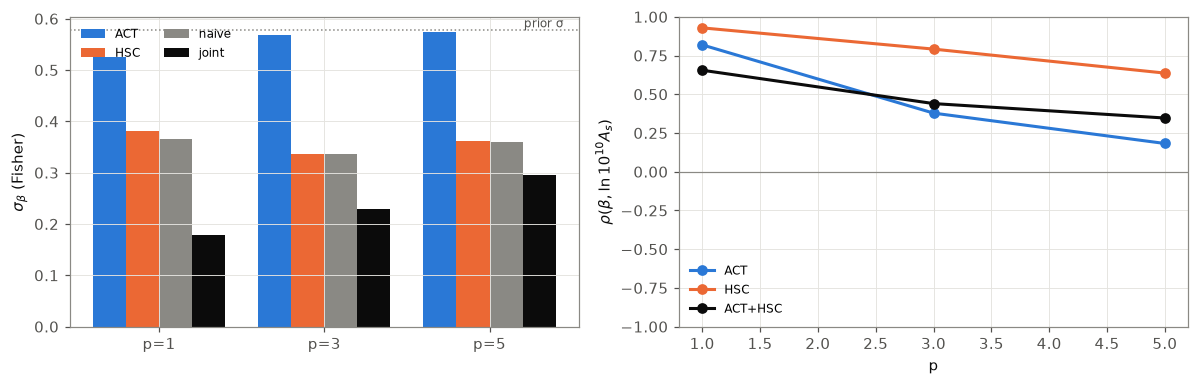

'\n左圖：每個 p 的 σ_β。naive（灰）= 兩組資料的 1D 資訊直接相加；黑色明顯低於灰色 → 簡併方向互補（synergy > 1）。點線 = flat prior 的 σ（0.577）。\n右圖：β 與 ln10^10 As 的相關係數。ACT 單獨時 |ρ| 大；若 ACT+HSC 的 |ρ| 明顯變小，表示 β–As 簡併被打破。\n'

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
w = 0.2; xs = np.arange(len(P_LIST))
for k, (lab, col) in enumerate([("sigma_ACT", COMBO_COLORS["ACT"]), ("sigma_HSC", COMBO_COLORS["HSC"]),
                                 ("sigma_naive", "#8a8984"), ("sigma_joint", COMBO_COLORS["ACT+HSC"])]):
    axs[0].bar(xs + (k - 1.5)*w, dfBreak[lab], width=w, color=col, label=lab.replace("sigma_", ""))
axs[0].axhline(SIG_PRIOR_BETA, color="#8a8984", ls=":", lw=1)
axs[0].text(xs[-1] + 0.45, SIG_PRIOR_BETA, "prior σ", va="bottom", ha="right", fontsize=8, color="#52514e")
axs[0].set(xticks=xs, xticklabels=[f"p={p}" for p in P_LIST], ylabel=r"$\sigma_\beta$ (Fisher)")
axs[0].legend(fontsize=8, ncol=2)

for k, c in enumerate(COMBOS):
    axs[1].plot(P_LIST, dfF[dfF.data == c].rho_beta_logA, "o-", color=COMBO_COLORS[c], label=c)
axs[1].axhline(0, color="#8a8984", lw=0.8)
axs[1].set(xlabel="p", ylabel=r"$\rho(\beta,\ln10^{10}A_s)$", ylim=(-1, 1)); axs[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

"""
左圖：每個 p 的 σ_β。naive（灰）= 兩組資料的 1D 資訊直接相加；黑色明顯低於灰色 → 簡併方向互補（synergy > 1）。點線 = flat prior 的 σ（0.577）。
右圖：β 與 ln10^10 As 的相關係數。ACT 單獨時 |ρ| 大；若 ACT+HSC 的 |ρ| 明顯變小，表示 β–As 簡併被打破。
"""

### B3. 2D Fisher 橢圓：$\beta$ 對 $\ln10^{10}A_s$、$\omega_c$、$H_0$、$S_8^{\rm CMBL}$、$S_8$

每列一個 $p$；藍 = ACT、橘 = HSC、黑 = ACT+HSC；實線 $1\sigma$（$\Delta\chi^2=2.30$）、虛線 $2\sigma$（6.18）；點線 = $\beta$ 的 flat prior 邊界。兩個橢圓**交叉**（主軸方向不同）就是聯合分析能打破簡併的幾何意義。

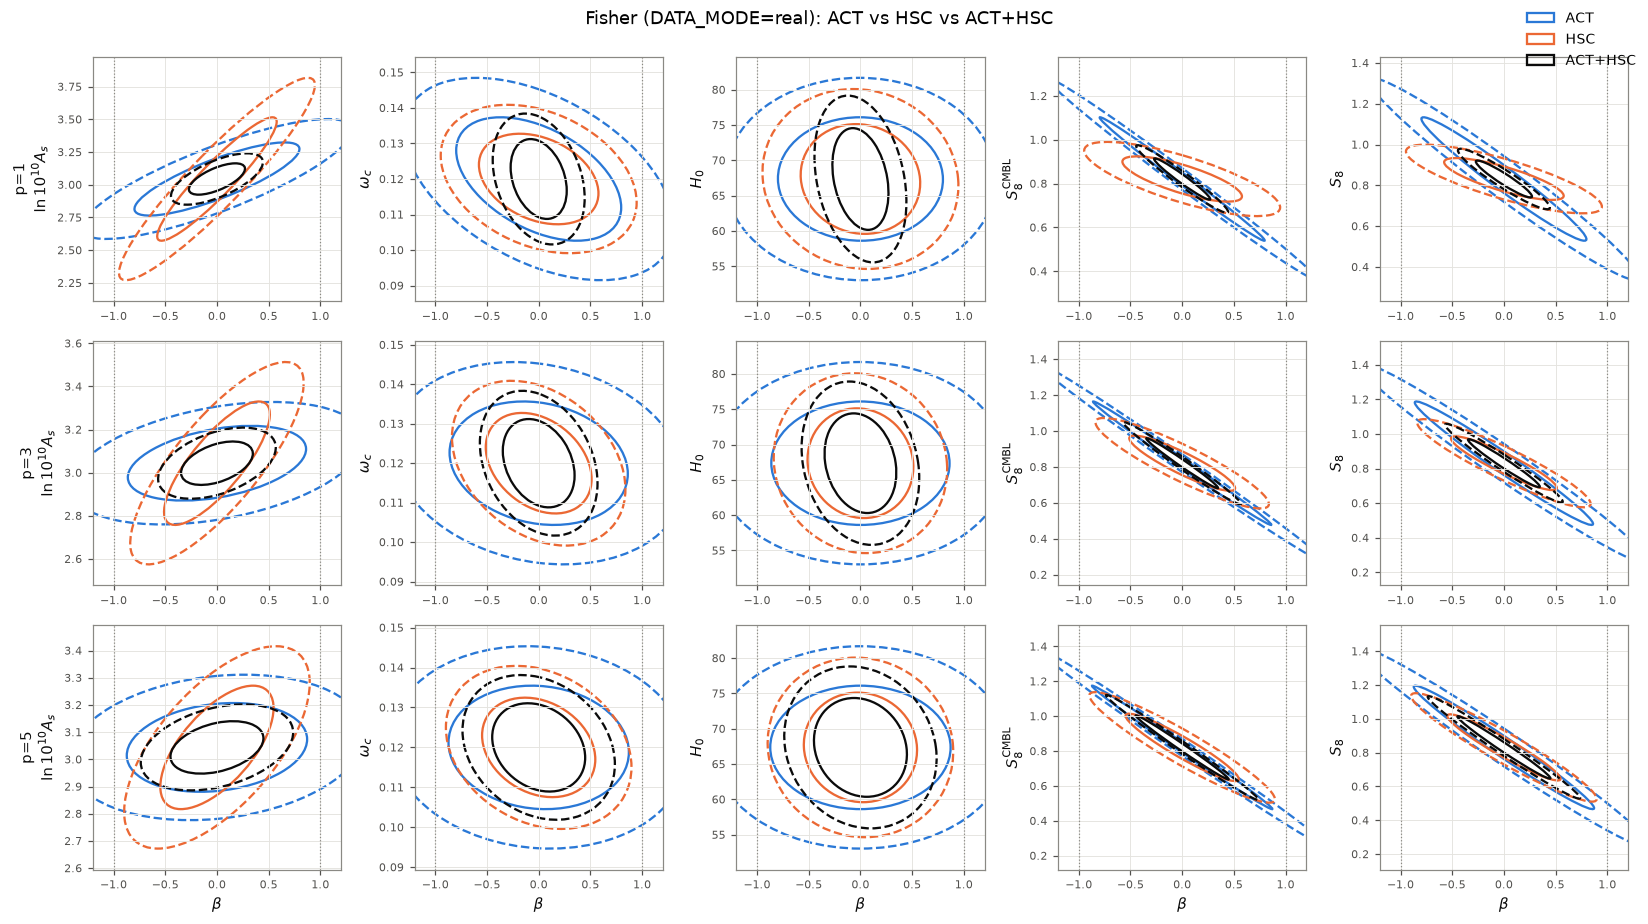

In [23]:
def ellipse(ax, C2, mu, color, label=None):
    w_, v_ = np.linalg.eigh(C2)
    ang = np.degrees(np.arctan2(v_[1, 1], v_[0, 1]))
    for k, ls in [(2.30, "-"), (6.18, "--")]:
        ax.add_patch(Ellipse(mu, 2*np.sqrt(k*w_[1]), 2*np.sqrt(k*w_[0]), angle=ang, fill=False,
                             ec=color, lw=1.5, ls=ls, label=label if ls == "-" else None))

def lin_vec(name):
    """參數或 derived 量對 PARS 的線性係數，以及 fiducial 值"""
    if name in PARS:
        v = np.zeros(len(PARS)); v[PARS.index(name)] = 1.0
        return v, THETA0[name]
    d = DERIVED.index(name)
    return GD[d], D0[d]

YQ = ["logA", "omch2", "H0", "S8CMBL_DETG", "S8_DETG"]
YLAB = {"logA": r"$\ln10^{10}A_s$", "omch2": r"$\omega_c$", "H0": r"$H_0$",
        "S8CMBL_DETG": r"$S_8^{\rm CMBL}$", "S8_DETG": r"$S_8$"}
vb, mb = lin_vec("beta_detg")
fig, axs = plt.subplots(len(P_LIST), len(YQ), figsize=(3.0*len(YQ), 2.8*len(P_LIST)), squeeze=False)
for r_, p in enumerate(P_LIST):
    for c_, q in enumerate(YQ):
        a = axs[r_, c_]; vq, mq = lin_vec(q)
        M = np.vstack([vb, vq]); sx = sy = 0.0
        for comb in COMBOS:
            C2 = M @ COV[comb][p] @ M.T
            ellipse(a, C2, (mb, mq), COMBO_COLORS[comb], label=comb)
            if comb != "ACT":
                sx, sy = max(sx, np.sqrt(C2[0, 0])), max(sy, np.sqrt(C2[1, 1]))
        sx = max(sx, float(np.sqrt((M @ COV["ACT"][p] @ M.T)[0, 0])))
        sy = max(sy, float(np.sqrt((M @ COV["ACT"][p] @ M.T)[1, 1])))
        a.set_xlim(max(mb - 3*sx, BETA_PRIOR[0] - 0.2), min(mb + 3*sx, BETA_PRIOR[1] + 0.2))
        a.set_ylim(mq - 3*sy, mq + 3*sy)
        for lim in BETA_PRIOR:
            a.axvline(lim, color="#8a8984", lw=0.8, ls=":")
        a.tick_params(labelsize=7)
        if r_ == len(P_LIST) - 1: a.set_xlabel(r"$\beta$")
        if c_ == 0: a.set_ylabel(f"p={p}\n" + YLAB[q])
        else: a.set_ylabel(YLAB[q])
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper right", fontsize=9)
fig.suptitle(f"Fisher (DATA_MODE={DATA_MODE}): ACT vs HSC vs ACT+HSC", y=0.995)
fig.tight_layout(); plt.show()

In [24]:
Z_S8 = [0.0] + [float(z) for z in MJ.likelihood[f"hsc_p{P_LIST[0]}"].z_l_eff] + [1.0, 2.0]

def ln_extra(theta, z, p):
    """ln S8(z) - ln σ8^DETG(0)；只用背景量"""
    h = theta["H0"]/100.0
    bg = ccl.Cosmology(Omega_c=theta["omch2"]/h**2, Omega_b=theta["ombh2"]/h**2, h=h, n_s=theta["ns"],
                       sigma8=0.8, m_nu=0.06, transfer_function="bbks")
    om = bg["Omega_m"]
    gr = GrowthModel("detg", om, par=theta["beta_detg"], p=p)
    a = 1.0/(1.0 + z)
    return (-0.5*np.log(1.0 - theta["beta_detg"]) + 0.5*np.log(gr.alpha(a))
            + np.log(ccl.growth_factor(bg, a)) + 0.5*np.log(om/0.3))

def grad_S8z(z, p):
    """回傳 (S8(z) 在 fiducial 的值, 對 PARS 的梯度)"""
    s8d = D0[DERIVED.index("sigma8_DETG")]
    g_ln = GD[DERIVED.index("sigma8_DETG")]/s8d
    e0 = ln_extra(THETA0, z, p)
    g_ex = np.zeros(len(PARS))
    for j, par in enumerate(PARS):
        if par not in COSMO + ["beta_detg"]:
            continue
        hh = STEPS[par]*0.5
        up, dn = dict(THETA0), dict(THETA0)
        up[par] += hh; dn[par] -= hh
        g_ex[j] = (ln_extra(up, z, p) - ln_extra(dn, z, p))/(2*hh)
    val = s8d*np.exp(e0)
    return val, val*(g_ln + g_ex)

idx_nb = [i for i in range(len(PARS)) if i != IB]
rowsS8 = []
GS8 = {}
for p in P_LIST:
    for z in Z_S8:
        val, g = grad_S8z(z, p); GS8[(p, z)] = (val, g)
        for comb in COMBOS:
            C_ = COV[comb][p]
            C_fix = inv_scaled(FISH[comb][p][np.ix_(idx_nb, idx_nb)])
            s_free = float(np.sqrt(g @ C_ @ g)); s_fix = float(np.sqrt(g[idx_nb] @ C_fix @ g[idx_nb]))
            rowsS8.append(dict(p=p, z=z, data=comb, S8z_fid=val, sigma_beta_free=s_free, sigma_beta_fixed=s_fix,
                               inflation=s_free/s_fix, rho_beta_S8z=float((g @ C_[:, IB])/np.sqrt(s_free**2*C_[IB, IB]))))
dfS8z = pd.DataFrame(rowsS8)
print("inflation = σ(β 自由)/σ(β 固定)；接近 1 且 |rho| 小 → 該紅移的振幅不受 β 影響")
display(dfS8z[dfS8z.data == "ACT+HSC"].pivot(index="z", columns="p", values=["inflation", "rho_beta_S8z"]).round(3))
dfS8z.round(4)

inflation = σ(β 自由)/σ(β 固定)；接近 1 且 |rho| 小 → 該紅移的振幅不受 β 影響


inflation               rho_beta_S8z              
p              1      3      5            1      3      5
z                                                        
0.0000     2.960  4.544  6.047       -0.941 -0.975 -0.986
0.2607     2.628  2.457  2.017       -0.925 -0.913 -0.868
0.5106     2.062  1.321  1.052       -0.874 -0.653 -0.311
0.6264     1.791  1.108  1.004       -0.830 -0.431 -0.088
1.0000     1.173  1.004  1.007       -0.523  0.090  0.121
2.0000     1.089  1.033  1.008        0.396  0.250  0.127

,p,z,data,S8z_fid,sigma_beta_free,sigma_beta_fixed,inflation,rho_beta_S8z
0,1,0.0000,ACT,0.8313,0.1995,0.0452,4.4186,-0.9741
1,1,0.0000,HSC,0.8313,0.0677,0.0404,1.6749,-0.8022
2,1,0.0000,ACT+HSC,0.8313,0.0597,0.0202,2.9600,-0.9412
3,1,0.2607,ACT,0.7238,0.1258,0.0318,3.9498,-0.9674
4,1,0.2607,HSC,0.7238,0.0376,0.0350,1.0748,-0.3664
5,1,0.2607,ACT+HSC,0.7238,0.0373,0.0142,2.6279,-0.9248
6,1,0.5106,ACT,0.6358,0.0769,0.0237,3.2413,-0.9512
7,1,0.5106,HSC,0.6358,0.0332,0.0310,1.0693,0.3542
8,1,0.5106,ACT+HSC,0.6358,0.0228,0.0110,2.0616,-0.8745
9,1,0.6264,ACT,0.6001,0.0607,0.0211,2.8804,-0.9378


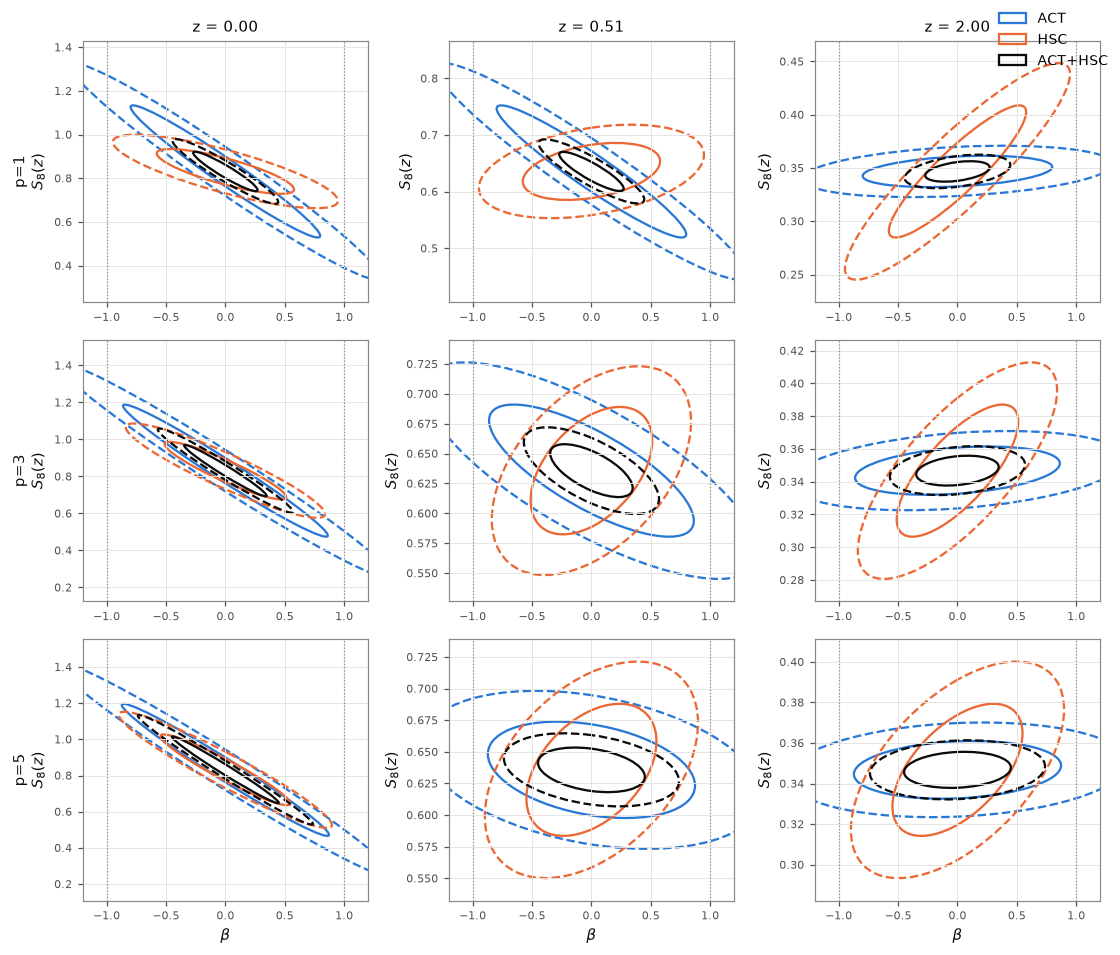

'\n每列一個 p，每欄一個紅移：z=0（S8 的慣用定義）、HSC 中間 lens bin 的 z_eff、z=2（ACT kernel 的範圍）。\n怎麼讀：z=0 的細長斜橢圓是外推因子 √α 造成的；在 HSC 的 z_eff，若 ACT+HSC（黑）的橢圓變得接近水平/直立，\n表示該紅移的振幅與 β 無關、被資料直接量準；z=2 時 β 的效應（α→1）變小，HSC 的橢圓方向會翻轉，這就是兩組資料互補的來源。\n'

In [25]:
Z_SHOW = [0.0, Z_S8[2], 2.0]                  # z=0、HSC 中間 lens bin、ACT 高紅移
fig, axs = plt.subplots(len(P_LIST), len(Z_SHOW), figsize=(3.4*len(Z_SHOW), 2.9*len(P_LIST)), squeeze=False)
vb = np.zeros(len(PARS)); vb[IB] = 1.0
for r_, p in enumerate(P_LIST):
    for c_, z in enumerate(Z_SHOW):
        a = axs[r_, c_]; val, g = GS8[(p, z)]
        M = np.vstack([vb, g]); sx = sy = 0.0
        for comb in COMBOS:
            C2 = M @ COV[comb][p] @ M.T
            ellipse(a, C2, (THETA0["beta_detg"], val), COMBO_COLORS[comb], label=comb)
            sx, sy = max(sx, np.sqrt(C2[0, 0])), max(sy, np.sqrt(C2[1, 1]))
        b0 = THETA0["beta_detg"]
        a.set_xlim(max(b0 - 3*sx, BETA_PRIOR[0] - 0.2), min(b0 + 3*sx, BETA_PRIOR[1] + 0.2))
        a.set_ylim(val - 3*sy, val + 3*sy)
        for lim in BETA_PRIOR:
            a.axvline(lim, color="#8a8984", lw=0.8, ls=":")
        a.tick_params(labelsize=7)
        if r_ == 0: a.set_title(f"z = {z:.2f}", fontsize=10)
        if r_ == len(P_LIST) - 1: a.set_xlabel(r"$\beta$")
        a.set_ylabel((f"p={p}\n" if c_ == 0 else "") + r"$S_8(z)$")
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper right", fontsize=9)
fig.tight_layout(); plt.show()

"""
每列一個 p，每欄一個紅移：z=0（S8 的慣用定義）、HSC 中間 lens bin 的 z_eff、z=2（ACT kernel 的範圍）。
怎麼讀：z=0 的細長斜橢圓是外推因子 √α 造成的；在 HSC 的 z_eff，若 ACT+HSC（黑）的橢圓變得接近水平/直立，
表示該紅移的振幅與 β 無關、被資料直接量準；z=2 時 β 的效應（α→1）變小，HSC 的橢圓方向會翻轉，這就是兩組資料互補的來源。
"""

### B4. 資料實際約束的方向數，以及 HSC 對「ACT 簡併方向」的懲罰

1. **Prior-whitened data Fisher** 的特徵值 $>1$ 的個數 = 資料比 prior 強的方向數（ACT notebook 中 ACT 只有 2/6）。
2. **ACT 簡併方向**：沿 ACT-only 的 profile 方向 $\Delta\boldsymbol\theta_c=\mathbf{C}^{\rm ACT}_{:,\beta}\Delta\beta/C^{\rm ACT}_{\beta\beta}$ 移動宇宙學參數，HSC nuisance 依 HSC Fisher 最佳化跟著調（$\Delta\mathbf n=-(F^{\rm HSC}+F^{\rm prior})_{nn}^{-1}F^{\rm HSC}_{nc}\Delta\boldsymbol\theta_c$，避免 nuisance 吸收的效應被誤算成懲罰）。列出在 $\Delta\beta=\sigma_\beta^{\rm ACT}$ 時 ACT 與 HSC 各自的 $\Delta\chi^2$（Fisher 預測）。**$\Delta\chi^2_{\rm HSC}\gg1$ 而 $\Delta\chi^2_{\rm ACT}\lesssim1$ → HSC 能排除 ACT 允許的方向。**

In [26]:
IDX_N = [PARS.index(k) for k in NUIS]
IDX_C = [i for i in range(len(PARS)) if i not in IDX_N]

def act_degeneracy_dir(p):
    C_ = COV["ACT"][p]
    u = C_[:, IB]/C_[IB, IB]
    u_c = np.zeros(len(PARS)); u_c[IDX_C] = u[IDX_C]
    if IDX_N:
        Fnn = (FH[p] + FP)[np.ix_(IDX_N, IDX_N)]
        Fnc = FH[p][np.ix_(IDX_N, IDX_C)]
        u_c[IDX_N] = -np.linalg.solve(Fnn, Fnc @ u_c[IDX_C])
    return u_c

def joint_profile_dir(p):
    C_ = COV["ACT+HSC"][p]
    return C_[:, IB]/C_[IB, IB]

U_ACT = {p: act_degeneracy_dir(p) for p in P_LIST}
U_J = {p: joint_profile_dir(p) for p in P_LIST}

FP_noB = FP.copy(); FP_noB[IB, IB] = 0.0
rows = []
for p in P_LIST:
    for lab, Fd in [("ACT", FA[p]), ("HSC", FH[p]), ("ACT+HSC", FA[p] + FH[p])]:
        lam = np.linalg.eigvalsh(Fd*np.outer(SIG_P, SIG_P))[::-1]
        rows.append(dict(p=p, data=lab, n_data_dominated=int((lam > 1).sum()), n_params=len(PARS),
                         top_eigs=np.array2string(lam[:8], precision=2)))
dfEig = pd.DataFrame(rows)
display(dfEig)

rows = []
for p in P_LIST:
    u = U_ACT[p]; db = float(np.sqrt(COV["ACT"][p][IB, IB]))
    rows.append(dict(p=p, dbeta=db, dchi2_ACT=float(u @ FA[p] @ u)*db**2, dchi2_HSC=float(u @ FH[p] @ u)*db**2,
                     dchi2_prior_nonbeta=float(u @ FP_noB @ u)*db**2,
                     **{f"d{k}_per_dbeta": float(u[PARS.index(k)]) for k in COSMO}))
dfPen = pd.DataFrame(rows)
print("沿 ACT 簡併方向移動 Δβ = σ_β(ACT)（Fisher 預測）：")
dfPen.round(4)

,p,data,n_data_dominated,n_params,top_eigs
0,1,ACT,2,17,[9.72e+02 1.64e+01 1.11e-01 1.41e-03 1.19e-04 ...
1,1,HSC,5,17,[3.40e+03 1.28e+03 1.00e+03 3.70e+02 4.08e+01 ...
2,1,ACT+HSC,6,17,[4.05e+03 1.29e+03 1.01e+03 6.02e+02 8.91e+01 ...
3,3,ACT,2,17,[9.55e+02 1.55e+01 2.63e-02 1.34e-03 1.20e-04 ...
4,3,HSC,6,17,[3.02e+03 1.29e+03 1.00e+03 3.70e+02 3.75e+01 ...
5,3,ACT+HSC,7,17,[3.68e+03 1.30e+03 1.01e+03 5.94e+02 8.76e+01 ...
6,5,ACT,2,17,[9.54e+02 1.54e+01 7.70e-03 1.29e-03 1.20e-04 ...
7,5,HSC,6,17,[2.96e+03 1.29e+03 1.00e+03 3.69e+02 3.47e+01 ...
8,5,ACT+HSC,7,17,[3.62e+03 1.30e+03 1.01e+03 5.93e+02 8.72e+01 ...


沿 ACT 簡併方向移動 Δβ = σ_β(ACT)（Fisher 預測）：


,p,dbeta,dchi2_ACT,dchi2_HSC,dchi2_prior_nonbeta,dombh2_per_dbeta,domch2_per_dbeta,dH0_per_dbeta,dns_per_dbeta,dlogA_per_dbeta
0,1,0.5261,0.1026,5.4373,4.3854,0.0,-0.0101,-0.0886,-0.0009,0.2868
1,3,0.5683,0.0251,4.0197,1.6511,0.0,-0.0031,-0.0333,-0.0002,0.0761
2,5,0.5750,0.0068,2.3576,0.6273,0.0,-0.0014,-0.0163,-0.0001,0.0341


### B5. Fisher 是否可信：沿兩個方向的 exact $\Delta\chi^2$（Asimov）

| 方向 | 移動 | 比較 |
|---|---|---|
| (i) ACT 簡併方向（B4） | $\Delta\beta=\sigma_\beta^{\rm ACT}\times\{-1,-\tfrac12,\tfrac12,1\}$ | exact vs Fisher 的 $\Delta\chi^2_{\rm ACT}$、$\Delta\chi^2_{\rm HSC}$ |
| (ii) joint profile 方向 | $\Delta\beta=\sigma_\beta^{\rm ACT+HSC}\times\{\pm1,\pm2,\pm3\}$ | exact vs Fisher 的資料項 $\Delta\chi^2_{\rm ACT}+\Delta\chi^2_{\rm HSC}$ |

$\beta$ 限制在 $[-0.95,0.95]$。`out_of_prior` 列出超出 flat prior 範圍的參數（posterior 會被截斷，Fisher 不能取代 MCMC）。(ii) 在 $\pm2\sigma$ 內的 $|\text{exact}/\text{Fisher}-1|$ 是 C 節的非 Gaussian 判準。

In [31]:
def chi2_split(point, p):
    TA, TH, _, _ = theory_all(point)
    da, dh = TA[p] - T0A[p], TH[p] - T0H[p]
    return float(da @ CINV_A @ da), float(dh @ CINV_H @ dh)

def out_of_bounds(point):
    return [k for k in PARS if not (PRI[k]["lo"] <= point[k] <= PRI[k]["hi"])]

def grid(sig, mults):
    bs = sorted({float(np.clip(THETA0["beta_detg"] + m*sig, -0.95, 0.95)) for m in mults})
    return [b for b in bs if b != THETA0["beta_detg"]]

CHECK = []
t0 = time.time()
for p in P_LIST:
    for dname, U, sig, mults in [("i ACT-degeneracy", U_ACT[p], float(np.sqrt(COV["ACT"][p][IB, IB])), [-1, -0.5, 0.5, 1]),
                                 ("ii joint-profile", U_J[p], float(np.sqrt(COV["ACT+HSC"][p][IB, IB])), [-3, -2, -1, 1, 2, 3])]:
        for b in grid(sig, mults):
            db = b - THETA0["beta_detg"]
            pt = {k: THETA0[k] + U[i]*db for i, k in enumerate(PARS)}
            fa, fh = float(U @ FA[p] @ U)*db**2, float(U @ FH[p] @ U)*db**2
            try:
                ea, eh = chi2_split(pt, p); note = ""
            except Exception as e:
                ea, eh, note = np.nan, np.nan, f"{e!r}"[:80]
            CHECK.append(dict(p=p, direction=dname, beta=b, nsig=db/sig, fisher_ACT=fa, exact_ACT=ea,
                              fisher_HSC=fh, exact_HSC=eh, ratio_total=(ea + eh)/(fa + fh) if fa + fh > 0 else np.nan,
                              out_of_prior=",".join(out_of_bounds(pt)), note=note))
print(f"done ({(time.time()-t0)/60:.1f} min)")
dfG = pd.DataFrame(CHECK)
dfG.round(4)

done (4.2 min)


,p,direction,beta,nsig,fisher_ACT,exact_ACT,fisher_HSC,exact_HSC,ratio_total,out_of_prior,note
0,1,i ACT-degeneracy,-0.5261,-1.0,0.1026,0.1130,5.4373,14.5763,2.6515,,
1,1,i ACT-degeneracy,-0.2630,-0.5,0.0256,0.0243,1.3593,1.8387,1.3452,,
2,1,i ACT-degeneracy,0.2630,0.5,0.0256,0.0328,1.3593,3.1771,2.3176,,
3,1,i ACT-degeneracy,0.5261,1.0,0.1026,0.1850,5.4373,34.9980,6.3508,,
4,1,ii joint-profile,-0.5365,-3.0,0.5285,0.6722,4.5039,14.6068,3.0361,,
5,1,ii joint-profile,-0.3576,-2.0,0.2349,0.2750,2.0018,3.9533,1.8905,,
6,1,ii joint-profile,-0.1788,-1.0,0.0587,0.0634,0.5004,0.5857,1.1607,,
7,1,ii joint-profile,0.1788,1.0,0.0587,0.0544,0.5004,0.8462,1.6105,,
8,1,ii joint-profile,0.3576,2.0,0.2349,0.2038,2.0018,6.9181,3.1842,,
9,1,ii joint-profile,0.5365,3.0,0.5285,0.4343,4.5039,29.6212,5.9724,,


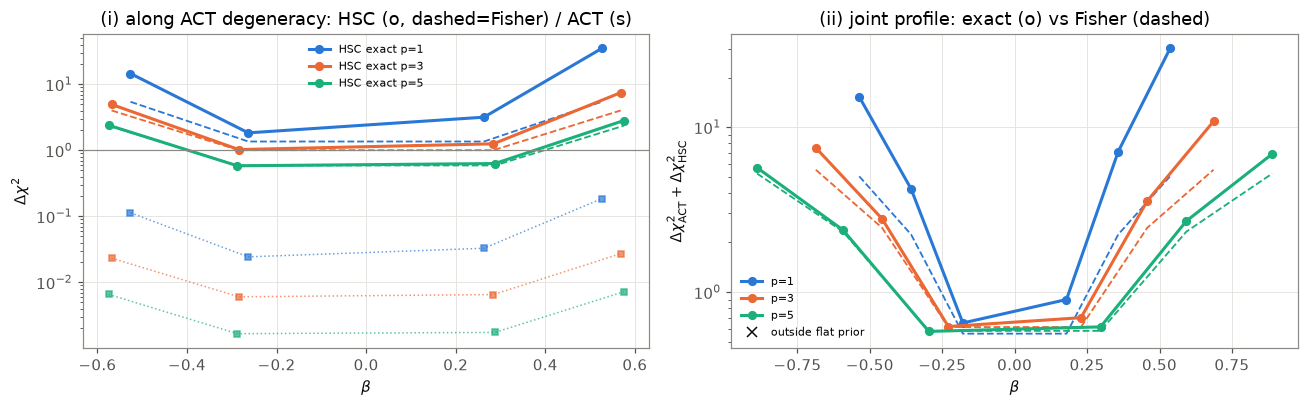

'\n左圖：沿 ACT 允許的方向（ACT 的 Δχ² 很小，方點）走時，HSC 的 Δχ²（圓點）。圓點遠高於 1 → HSC 排除這個方向。\n右圖：沿 joint profile 方向的總 Δχ²；實線與虛線重疊 → Fisher 可信；× 表示其他參數超出 flat prior。\n'

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for k, p in enumerate(P_LIST):
    s_ = dfG[(dfG.p == p) & (dfG.direction == "i ACT-degeneracy")]
    axs[0].plot(s_.beta, s_.exact_HSC, "o-", color=COLORS[k], ms=5, label=f"HSC exact p={p}")
    axs[0].plot(s_.beta, s_.fisher_HSC, "--", color=COLORS[k], lw=1.2)
    axs[0].plot(s_.beta, s_.exact_ACT, "s:", color=COLORS[k], ms=4, lw=1, alpha=0.7)
    s_ = dfG[(dfG.p == p) & (dfG.direction == "ii joint-profile")]
    axs[1].plot(s_.beta, s_.exact_ACT + s_.exact_HSC, "o-", color=COLORS[k], ms=5, label=f"p={p}")
    axs[1].plot(s_.beta, s_.fisher_ACT + s_.fisher_HSC, "--", color=COLORS[k], lw=1.2)
    off = s_[s_.out_of_prior != ""]
    axs[1].plot(off.beta, off.exact_ACT + off.exact_HSC, "x", color="#0b0b0b", ms=9, mew=1.5)
axs[0].axhline(1, color="#8a8984", lw=0.8)
axs[0].set(xlabel=r"$\beta$", ylabel=r"$\Delta\chi^2$", yscale="log",
           title="(i) along ACT degeneracy: HSC (o, dashed=Fisher) / ACT (s)")
axs[1].set(xlabel=r"$\beta$", ylabel=r"$\Delta\chi^2_{\rm ACT}+\Delta\chi^2_{\rm HSC}$", yscale="log",
           title="(ii) joint profile: exact (o) vs Fisher (dashed)")
axs[1].plot([], [], "x", color="#0b0b0b", label="outside flat prior")
axs[0].legend(fontsize=7); axs[1].legend(fontsize=7); fig.tight_layout(); plt.show()

"""
左圖：沿 ACT 允許的方向（ACT 的 Δχ² 很小，方點）走時，HSC 的 Δχ²（圓點）。圓點遠高於 1 → HSC 排除這個方向。
右圖：沿 joint profile 方向的總 Δχ²；實線與虛線重疊 → Fisher 可信；× 表示其他參數超出 flat prior。
"""

In [32]:
dfGN = None
if RUN_GN:
    DA = MJ.likelihood[f"act_p{P_LIST[0]}"].data["data_binned_clkk"]
    DH = MJ.likelihood[f"hsc_p{P_LIST[0]}"].data_vector
    GMASK = np.array([is_gauss(k) for k in PARS], dtype=float)
    FG = np.diag(GMASK/SIG_P**2)
    MU = np.array([PRI[k]["mean"] for k in PARS])
    LO = np.array([PRI[k]["lo"] for k in PARS]); HI = np.array([PRI[k]["hi"] for k in PARS])
    HI[IB] = min(HI[IB], 0.95)
    span = HI - LO
    pad = np.where(np.isfinite(span), 1e-3*span, 0.0)       # Gaussian prior 的 bounds 是 ±inf：不能用 inf*1e-3（-inf+inf=NaN）
    rows = []
    for p in P_LIST:
        th = np.array([THETA0[k] for k in PARS])
        Cj = COV["ACT+HSC"][p]
        for it in range(N_GN + 1):
            pt = dict(zip(PARS, th))
            try:
                TA, TH, Dv, _ = theory_all(pt)
            except Exception as e:
                print(f"p={p} iter {it}: 求值失敗 {e!r}"); break
            ra, rh = DA - TA[p], DH - TH[p]
            chi_a, chi_h = float(ra @ CINV_A @ ra), float(rh @ CINV_H @ rh)
            chi_pr = float((th - MU) @ FG @ (th - MU))
            rows.append(dict(p=p, iter=it, chi2_ACT=chi_a, chi2_HSC=chi_h, chi2_gauss_prior=chi_pr,
                             chi2_total=chi_a + chi_h + chi_pr, beta=th[IB], sigma_beta=float(np.sqrt(Cj[IB, IB])),
                             S8_DETG=Dv[1], S8CMBL_DETG=Dv[2], **{k: th[PARS.index(k)] for k in COSMO}))
            if it == N_GN: break
            grad = JA[p].T @ CINV_A @ ra + JH[p].T @ CINV_H @ rh + FG @ (MU - th)
            th = np.clip(th + Cj @ grad, LO + pad, HI - pad)
    dfGN = pd.DataFrame(rows)
    if DATA_MODE == "mock":
        print("⚠ mock 模式：ACT 的資料是 fiducial theory，以下 beta 估計中 ACT 部分沒有意義")
    display(dfGN.round(4))
    fin = dfGN.groupby("p").tail(1)
    for _, r in fin.iterrows():
        lo2, hi2 = r.beta - 2*r.sigma_beta, r.beta + 2*r.sigma_beta
        print(f"p={int(r.p)}: beta_hat = {r.beta:+.3f} ± {r.sigma_beta:.3f}（{r.beta/r.sigma_beta:+.1f}σ from 0）；"
              f"±2σ = [{lo2:+.2f}, {hi2:+.2f}]" + ("  ⚠ 碰到 prior 邊界" if (lo2 <= BETA_PRIOR[0] or hi2 >= BETA_PRIOR[1]) else ""))
else:
    print("RUN_GN=False，略過。")

,p,iter,chi2_ACT,chi2_HSC,chi2_gauss_prior,chi2_total,beta,sigma_beta,S8_DETG,S8CMBL_DETG,ombh2,omch2,H0,ns,logA
0,1,0,14.1012,226.5468,0.1969,240.8449,0.0000,0.1788,0.8313,0.8211,0.0224,0.1200,67.3600,0.9649,3.0440
1,1,1,13.6230,71.0559,0.5599,85.2387,0.0806,0.1788,0.8022,0.7875,0.0223,0.1150,65.3526,0.9580,3.1050
2,1,2,13.6681,70.3198,0.5547,84.5427,0.0887,0.1788,0.8013,0.7822,0.0223,0.1130,64.1480,0.9591,3.1184
3,1,3,13.7130,70.2516,0.5721,84.5366,0.0976,0.1788,0.8004,0.7777,0.0223,0.1120,63.3094,0.9596,3.1252
4,1,4,13.7554,70.1441,0.6014,84.5009,0.1073,0.1788,0.7985,0.7732,0.0223,0.1112,62.7149,0.9599,3.1302
5,3,0,14.1012,226.5468,0.1969,240.8449,0.0000,0.2288,0.8313,0.8211,0.0224,0.1200,67.3600,0.9649,3.0440
6,3,1,13.5688,71.0176,0.6449,85.2313,0.0904,0.2288,0.7922,0.7789,0.0223,0.1151,65.5900,0.9581,3.0932
7,3,2,13.6161,70.3596,0.6286,84.6043,0.1017,0.2288,0.7889,0.7721,0.0223,0.1134,64.5744,0.9591,3.1051
8,3,3,13.6513,70.3112,0.6527,84.6152,0.1093,0.2288,0.7875,0.7680,0.0223,0.1125,63.8975,0.9595,3.1097
9,3,4,13.6823,70.2220,0.6897,84.5940,0.1181,0.2288,0.7850,0.7636,0.0223,0.1119,63.4410,0.9598,3.1126


p=1: beta_hat = +0.107 ± 0.179（+0.6σ from 0）；±2σ = [-0.25, +0.46]
p=3: beta_hat = +0.118 ± 0.229（+0.5σ from 0）；±2σ = [-0.34, +0.58]
p=5: beta_hat = +0.144 ± 0.296（+0.5σ from 0）；±2σ = [-0.45, +0.74]


## C. 結論：ACT+HSC 是否解決簡併、是否值得跑 MCMC

| 判準 | 意義 | 門檻 |
|---|---|---|
| pipeline 驗證 | A 節中 `affects="Fisher"` 的項目全部通過（否則 Fisher 不可信）；`affects="MCMC"` 的項目（A4、A6）只影響之後的 sampler run | 全部 pass |
| data-dominated | $\sigma_\beta^{\rm ACT+HSC}/\sigma_{\rm prior}$；小表示資料（不是 prior）決定 $\beta$ | $<0.5$ |
| 打破簡併 | gain $=\sigma_\beta^{\rm ACT}/\sigma_\beta^{\rm ACT+HSC}$，以及 synergy（簡併方向互補） | gain $\ge2$ 且 synergy $\ge1.2$ |
| $\beta$–$A_s$ 去相關 | $|\rho(\beta,\ln10^{10}A_s)|$（joint） | $<0.7$ |
| 非 Gaussian | B5(ii) 在 $\pm2\sigma$ 內 $|\text{exact}/\text{Fisher}-1|$ 最大值 | $>0.2$ |
| 撞到邊界 | $\beta_0\pm2\sigma_\beta$ 碰到 $\pm1$，或 B5(ii) $\pm2\sigma$ 內其他參數超出 prior；B6 的 $\hat\beta\pm2\sigma$ 亦同 | 任何一項 |

**決策**
- A 節影響 Fisher 的項目未通過 → 先修 pipeline。
- 結論值得跑 MCMC，但 A4/A6 未通過 → 先修 `hsc_lens.py`（見 A4、A6 的說明）再跑。
- A3b（IA 成長正規化）的 $\Delta\chi^2$ 若不小，正式 MCMC 前要決定是否採用修正。
- 不是 data-dominated → 聯合後 $\beta$ 仍由 prior 決定，MCMC 只會回到 prior：**暫不值得**（考慮加資料、換參數化或固定 $p$ 的範圍）。
- data-dominated 且打破簡併：Gaussian 且不撞邊界 → **值得跑 MCMC**（預期 posterior ≈ Fisher，MCMC 為正式結果）；非 Gaussian 或撞邊界 → **必須跑 MCMC**（Fisher 不能代替）。
- data-dominated 但 synergy ≈ 1 → $\beta$ 的資訊主要來自單一資料集，聯合的好處只是資訊相加；仍可跑 MCMC，但要清楚說明約束來源。

In [33]:
THR = dict(data_dom=0.5, gain=2.0, synergy=1.2, rho=0.7, nongauss=0.2)

def verdict(p):
    br = dfBreak[dfBreak.p == p].iloc[0]
    Fj = dfF[(dfF.p == p) & (dfF.data == "ACT+HSC")].iloc[0]
    g = dfG[(dfG.p == p) & (dfG.direction == "ii joint-profile") & (dfG.nsig.abs() <= 2.0 + 1e-9)]
    ng = float(np.nanmax(np.abs(g.ratio_total - 1))) if len(g) else np.nan
    sb = float(Fj.sigma_beta); b0 = THETA0["beta_detg"]
    hit = bool(b0 - 2*sb <= BETA_PRIOR[0] or b0 + 2*sb >= BETA_PRIOR[1] or (g.out_of_prior != "").any())
    if dfGN is not None:
        last = dfGN[dfGN.p == p].tail(1)
        if len(last):
            bh = float(last.beta.iloc[0])
            hit = hit or bool(bh - 2*sb <= BETA_PRIOR[0] or bh + 2*sb >= BETA_PRIOR[1])
    data_dom = sb/SIG_PRIOR_BETA < THR["data_dom"]
    breaks = br.gain_vs_ACT >= THR["gain"] and br.synergy >= THR["synergy"]
    decor = abs(Fj.rho_beta_logA) < THR["rho"]
    nongauss = np.isfinite(ng) and ng > THR["nongauss"]
    if not A_FISHER_OK:
        concl = "A 節影響 Fisher 的項目未通過：先修 pipeline，以下 Fisher 數字僅供參考"
    elif not data_dom:
        concl = "聯合後 β 仍由 prior 主導：MCMC 只會回到 prior，暫不值得"
    elif breaks and not (nongauss or hit):
        concl = "ACT+HSC 有效打破簡併且近 Gaussian：值得跑 MCMC（預期 ≈ Fisher）"
    elif breaks:
        concl = "ACT+HSC 有效打破簡併，但" + "、".join([s for s, f in [("非 Gaussian", nongauss), ("撞到 prior 邊界", hit)] if f]) \
                + "：必須跑 MCMC"
    else:
        concl = "β 已由資料決定，但 synergy/gain 有限（資訊主要來自單一資料集）：可跑 MCMC，需說明約束來源"
    return dict(p=p, sigma_beta_ACT=br.sigma_ACT, sigma_beta_joint=sb, sigma_over_prior=sb/SIG_PRIOR_BETA,
                gain_vs_ACT=br.gain_vs_ACT, synergy=br.synergy, rho_beta_logA_joint=Fj.rho_beta_logA,
                max_nongauss_2sig=ng, hits_prior=hit, data_dominated=data_dom, breaks_degeneracy=bool(breaks),
                beta_As_decorrelated=bool(decor), conclusion=concl,
                before_MCMC="" if A_MCMC_OK else "先修 A4/A6（hsc_lens.py）")

dfC = pd.DataFrame([verdict(p) for p in P_LIST])
pd.set_option("display.max_colwidth", 120)
print(f"DATA_MODE = {DATA_MODE}" + ("   ⚠ ACT 為 mock covariance：ACT 部分只是量級估計" if DATA_MODE == "mock" else ""))
print("A 節（影響 Fisher）全部通過：", A_FISHER_OK, "| A 節（只影響 MCMC）全部通過：", A_MCMC_OK)
print("A3b IA 成長正規化 dchi2_HSC（beta=BETA_TEST）：", {int(r.p): round(r.dchi2_HSC, 4) for _, r in dfIA.iterrows()})
dfC.round(4)

DATA_MODE = real
A 節（影響 Fisher）全部通過： True | A 節（只影響 MCMC）全部通過： True
A3b IA 成長正規化 dchi2_HSC（beta=BETA_TEST）： {1: 0.0007, 3: 0.0, 5: 0.0}


,p,sigma_beta_ACT,sigma_beta_joint,sigma_over_prior,gain_vs_ACT,synergy,rho_beta_logA_joint,max_nongauss_2sig,hits_prior,data_dominated,breaks_degeneracy,beta_As_decorrelated,conclusion,before_MCMC
0,1,0.5261,0.1788,0.3097,2.9418,2.0421,0.6552,2.1842,False,True,True,True,ACT+HSC 有效打破簡併，但非 Gaussian：必須跑 MCMC,
1,3,0.5683,0.2288,0.3964,2.4835,1.4663,0.4399,0.4551,False,True,True,True,ACT+HSC 有效打破簡併，但非 Gaussian：必須跑 MCMC,
2,5,0.5750,0.2964,0.5134,1.9401,1.2159,0.3466,0.1601,False,False,False,True,聯合後 β 仍由 prior 主導：MCMC 只會回到 prior，暫不值得,


In [34]:
# 存檔，方便之後與 MCMC 結果比較
out = f"{WORK_DIR}/fisher_joint_{DATA_MODE}.npz"
np.savez(out, params=np.array(PARS), theta0=np.array([THETA0[k] for k in PARS]), prior_sigma=SIG_P,
         derived=np.array(DERIVED), D0=D0,
         **{f"FA_p{p}": FA[p] for p in P_LIST}, **{f"FH_p{p}": FH[p] for p in P_LIST}, FP=FP,
         **{f"JA_p{p}": JA[p] for p in P_LIST}, **{f"JH_p{p}": JH[p] for p in P_LIST}, G=GD,
         cinv_act=CINV_A, cinv_hsc=CINV_H)
summaryA.to_csv(f"{WORK_DIR}/joint_validation_{DATA_MODE}.csv", index=False)
dfIA.to_csv(f"{WORK_DIR}/joint_IA_growth_impact_{DATA_MODE}.csv", index=False)
dfF.to_csv(f"{WORK_DIR}/joint_fisher_{DATA_MODE}.csv", index=False)
dfG.to_csv(f"{WORK_DIR}/joint_exact_vs_fisher_{DATA_MODE}.csv", index=False)
dfC.to_csv(f"{WORK_DIR}/joint_verdict_{DATA_MODE}.csv", index=False)
print("saved:", out)

saved: ./detg_joint_work/fisher_joint_real.npz
